# **Transformer-Based Diabetic Retinopathy Severity Grading Using Enhanced Fundus Images**

## **Import Required Libraries**

In [ ]:
!pip install -q keras-hub
!pip install -q --no-deps tfswin

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Import Required Libraries
import os
import random
import warnings
from pathlib import Path
from IPython.display import display, HTML
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
import cv2
from PIL import Image, ImageFile
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,cohen_kappa_score,roc_curve,auc
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")

from tfswin import SwinTransformerTiny224
import tensorflow as tf
import keras
import keras_hub

## **Reusable Configuration**

In [ ]:
# Set Random Seeds
SEED = 42
# Python random seed
random.seed(SEED)

# NumPy random seed
np.random.seed(SEED)

# Set OpenCV random seed
cv2.setRNGSeed(SEED)

# Set Matplotlib display configuration
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
print("Random seed configured:", SEED)

Random seed configured: 42


## **Dataset Configuration**

In [ ]:
# Exact Kaggle dataset path
DATASET_PATH = "/kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images"

# Actual image directory
IMAGE_DATASET_PATH = os.path.join(DATASET_PATH,"Diabetic Retinopathy","colored_images")
# Expected classification categories
CLASS_NAMES = ["No_DR","Mild","Moderate","Severe","Proliferate_DR"]

# Number of classification categories
NUM_CLASSES = len(CLASS_NAMES)

# Image configuration
IMAGE_SIZE = 224
IMAGE_CHANNELS = 3

# Data splitting configuration
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

# Supported image formats
IMAGE_EXTENSIONS = {".jpg",".jpeg",".png",".bmp",".tif",".tiff"}

# Visualisation colour palette
PALETTE = ["#c2785e","#a15b43","#803f29","#612410","#430800"]

# Plot formatting
TITLE_SIZE = 16
LABEL_SIZE = 13
ANNOTATION_SIZE = 10

TEXT_COLOR = "#666666"
GRID_COLOR = "#d9d9d9"
# Display the Dataset Configuration
print("Dataset path:", DATASET_PATH)
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Number of classes:", NUM_CLASSES)

Dataset path: /kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images
Image size: 224 x 224
Number of classes: 5


## **Dataset Understanding**

In [ ]:
# Display the main dataset directory
print("Dataset Root Directory:")
print
 (DATASET_PATH)
# Display the Dataset Folders
print("Dataset Folder Structure")
print("-" * 50)
# Traverse the dataset directories
for root, dirs, files in os.walk(DATASET_PATH):
    # Calculate directory depth
    level = root.replace(DATASET_PATH, "").count(os.sep)
    # Limit the displayed directory depth
    if level <= 3:
        indent = "    " * level
        print(indent + os.path.basename(root) + "/")
        # Display a maximum of five files per directory
        if level < 3:
            for filename in files[:5]:
                print(indent + "    " + filename)

Dataset Root Directory:
/kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images
Dataset Folder Structure
--------------------------------------------------
diabetic-retinopathy-fundus-images/
    Diabetic Retinopathy/
        colored_images/
            Mild/
            Moderate/
            No_DR/
            Proliferate_DR/
            Severe/


In [ ]:
# Find all subdirectories in the dataset
all_directories = []
for root, dirs, files in os.walk(DATASET_PATH):
    for directory in dirs:
        all_directories.append(Path(root) / directory)
# Store the identified class directories
CLASS_DIRS = {}

# Match folder names with expected class names
for class_name in CLASS_NAMES:
    matches = [folder for folder in all_directories if folder.name.lower() == class_name.lower() ]
    if len(matches) == 1:
        CLASS_DIRS[class_name] = matches[0]
    elif len(matches) == 0:
        print(f"Class directory not found: {class_name}")
    else:
        print(f"Multiple matching directories found: {class_name}")
        for folder in matches:
            print(" ", folder)

# Display identified directories
if len(CLASS_DIRS) == NUM_CLASSES:
    print("All five class directories identified successfully!")
    for class_name, class_path in CLASS_DIRS.items():
        print(f"{class_name}: {class_path}")
else:
    print("Class directory identification requires inspection.")

All five class directories identified successfully!
No_DR: /kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images/Diabetic Retinopathy/colored_images/No_DR
Mild: /kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images/Diabetic Retinopathy/colored_images/Mild
Moderate: /kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images/Diabetic Retinopathy/colored_images/Moderate
Severe: /kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images/Diabetic Retinopathy/colored_images/Severe
Proliferate_DR: /kaggle/input/datasets/dokkuvenkatalakshmi/diabetic-retinopathy-fundus-images/Diabetic Retinopathy/colored_images/Proliferate_DR


In [ ]:
# Store image paths class-wise
class_image_paths = {}

# Collect supported images from each class
for class_name, class_path in CLASS_DIRS.items():
    image_files = sorted([
        str(file)
        for file in class_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ])
    class_image_paths[class_name] = image_files

# Display image counts
print("Class wise image distribution")
print("-" * 50)
for class_name, image_paths in class_image_paths.items():
    print(f"{class_name:<20}: " f"{len(image_paths):>5} images" )

# Calculate total image count
total_images = sum(len(paths) for paths in class_image_paths.values())
print("-" * 50)
print("Total Images:", total_images)

Class wise image distribution
--------------------------------------------------
No_DR               :  1805 images
Mild                :   370 images
Moderate            :   999 images
Severe              :   193 images
Proliferate_DR      :   295 images
--------------------------------------------------
Total Images: 3662


In [ ]:
# Store image information
image_records = []

# Extract image paths and labels
for class_name, image_paths in class_image_paths.items():
    for image_path in image_paths:
        image_records.append({"image_path": image_path,"class_name": class_name })

# Create a Pandas DataFrame
image_df = pd.DataFrame(image_records)

# Display the first five records
print("Image Metadata Preview")
display(image_df.head())

# Display dataset information
print("Dataset Information")
print("-" * 40)
print("Total image records:", len(image_df))
print("Unique classes:", image_df["class_name"].nunique())
print("Missing image paths:", image_df["image_path"].isnull().sum())

Image Metadata Preview


,image_path,class_name
0,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
1,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
2,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
3,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
4,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR


Dataset Information
----------------------------------------
Total image records: 3662
Unique classes: 5
Missing image paths: 0


In [ ]:
# Lists to store validation results
valid_images = []
corrupted_images = []
def _validate_single_image(image_path):
  """Helper function to validate a single image."""
  try:
    with Image.open(image_path) as img:
      img.verify()
    with Image.open(image_path) as img:
      img.load()
    return image_path, True
  except Exception:
    return image_path, False
paths = list(image_df["image_path"])

# Run validation in parallel with a tqdm progress bar
with ThreadPoolExecutor() as executor:
  results = list(tqdm(executor.map(_validate_single_image, paths),total=len(paths),desc="Validating Images",))

# Populate lists based on results
for image_path, is_valid in results:
  if is_valid:
    valid_images.append(image_path)
  else:
    corrupted_images.append(image_path)

# Display validation summary
print("IMAGE VALIDATION RESULTS")
print("-" * 45)
print("Total images checked:", len(image_df))
print("Valid images:", len(valid_images))
print("Corrupted or unreadable images:", len(corrupted_images))
print("-" * 45)

# Display corrupted image paths if any
if corrupted_images:
  print("Corrupted image files:")
  for image_path in corrupted_images[:20]:
    print(image_path)
else:
  print("All images passed validation!")

Validating Images: 100%|██████████| 3662/3662 [00:25<00:00, 143.27it/s]

IMAGE VALIDATION RESULTS
---------------------------------------------
Total images checked: 3662
Valid images: 3662
Corrupted or unreadable images: 0
---------------------------------------------
All images passed validation!


In [ ]:
# Keep only images that passed validation
image_df = image_df[image_df["image_path"].isin(valid_images)].reset_index(drop=True)

# Display final validated dataset information
print("Validated Dataset Summary")
print("-" * 45)
print("Total valid images:", len(image_df))
print("Class-wise validated image counts:")
display(image_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).rename("Image Count").to_frame())

Validated Dataset Summary
---------------------------------------------
Total valid images: 3662
Class-wise validated image counts:


,Image Count
class_name,
No_DR,1805
Mild,370
Moderate,999
Severe,193
Proliferate_DR,295


## **Basic Dataset Statistics**

In [ ]:
# Calculate the total number of validated images
total_images = len(image_df)

# Calculate the number of unique classes
total_classes = image_df["class_name"].nunique()

# Display dataset information
print("Dataset Overview")
print("=" * 45)
print(f"Total Images       : {total_images}")
print(f"Total Classes      : {total_classes}")
print("Classification Categories:")
for index, class_name in enumerate(CLASS_NAMES, start=1):
    print(f"{index}. {class_name}")
print("=" * 45)

Dataset Overview
Total Images       : 3662
Total Classes      : 5
Classification Categories:
1. No_DR
2. Mild
3. Moderate
4. Severe
5. Proliferate_DR


In [ ]:
# Calculate the number of images in each class
class_statistics = (image_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).rename("Image Count").to_frame())

# Calculate percentage distribution
class_statistics["Percentage"] = (class_statistics["Image Count"] / total_images) * 100

# Format percentage values
class_statistics["Percentage"] = (class_statistics["Percentage"].round(2))

# Display statistical results
print("Class wise dataset statistics")
print("=" * 55)
display(class_statistics)
print("Total Image Count:", class_statistics["Image Count"].sum())
print("Total Percentage:",round(class_statistics["Percentage"].sum(), 2), "%")

Class wise dataset statistics


,Image Count,Percentage
class_name,,
No_DR,1805,49.29
Mild,370,10.10
Moderate,999,27.28
Severe,193,5.27
Proliferate_DR,295,8.06


Total Image Count: 3662
Total Percentage: 100.0 %


In [ ]:
# Store image properties
image_properties = []

# Analyse every validated image
for _, row in image_df.iterrows():
    image_path = row["image_path"]
    class_name = row["class_name"]
    try:
        # Open image and convert to RGB
        with Image.open(image_path) as img:
            rgb_image = img.convert("RGB")

            # Extract original image dimensions
            width, height = rgb_image.size

            # Convert image into NumPy array
            image_array = np.asarray(rgb_image)

            # Calculate average RGB channel intensities
            red_mean = image_array[:, :, 0].mean()
            green_mean = image_array[:, :, 1].mean()
            blue_mean = image_array[:, :, 2].mean()

            # Store extracted properties
            image_properties.append({
                "image_path": image_path,
                "class_name": class_name,
                "width": width,
                "height": height,
                "red_mean": red_mean,
                "green_mean": green_mean,
                "blue_mean": blue_mean
            })
    except Exception as error:
        print("Error processing:", image_path)
        print("Reason:", error)

# Create image properties DataFrame
image_stats_df = pd.DataFrame(image_properties)
print("Image property extraction completed!")
print("Analysed images:", len(image_stats_df))

Image property extraction completed!
Analysed images: 3662


In [ ]:
# Image Dimension Statistics
# Calculate width and height statistics
dimension_statistics = image_stats_df[["width", "height"]].describe().round(2)
print("Image Dimension Statistics")
print("=" * 45)
display(dimension_statistics)
# Identify unique image resolutions
unique_dimensions = (image_stats_df[["width", "height"]].value_counts().reset_index(name="Image Count"))
print("Most Common Image Resolutions:")
display(unique_dimensions.head(10))

Image Dimension Statistics


,width,height
count,3662.0,3662.0
mean,224.0,224.0
std,0.0,0.0
min,224.0,224.0
25%,224.0,224.0
50%,224.0,224.0
75%,224.0,224.0
max,224.0,224.0


Most Common Image Resolutions:


,width,height,Image Count
0,224,224,3662


In [ ]:
# RGB Channel Statistics
# Calculate descriptive statistics for RGB channels
rgb_statistics = image_stats_df[["red_mean", "green_mean", "blue_mean"]].describe().round(2)

# Rename columns for readability
rgb_statistics.columns = ["Red Channel","Green Channel","Blue Channel"]
print("RGB Channel Intensity Statics")
print("=" * 55)
display(rgb_statistics)

# Calculate overall average channel intensities
average_rgb = image_stats_df[["red_mean", "green_mean", "blue_mean"]].mean().round(2)
print("Average RGB Channel Intensities:")
display(average_rgb.to_frame(name="Average Intensity"))

RGB Channel Intensity Statics


,Red Channel,Green Channel,Blue Channel
count,3662.00,3662.00,3662.00
mean,105.44,56.28,18.71
std,30.92,15.71,14.67
min,29.25,10.49,0.04
25%,77.04,44.53,8.54
50%,111.66,57.04,14.57
75%,130.89,67.71,24.78
max,216.66,121.86,105.40


Average RGB Channel Intensities:


,Average Intensity
red_mean,105.44
green_mean,56.28
blue_mean,18.71


## **Image Visual Analysis**

In [ ]:
# Common Visualisation Configuration
PALETTE = ["#c2785e", "#a15b43", "#803f29", "#612410", "#430800"]

# Define common plot font sizes
TITLE_SIZE = 16
LABEL_SIZE = 13
ANNOTATION_SIZE = 10

# Define common text and grid colours
TEXT_COLOR = "#000000"
GRID_COLOR = "#d9d9d9"

# Define the default figure size
FIGURE_SIZE = (8, 5)

In [ ]:
# Define a reusable function for consistent plot formatting
def format_plot(ax, title, xlabel=None, ylabel=None):

    # Set the plot title
    ax.set_title(title, fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR, pad=15)

    # Set the X-axis label when provided
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)

    # Set the Y-axis label when provided
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)

    # Format tick labels on both axes
    ax.tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

    # Make tick labels bold and grey
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
        label.set_color(TEXT_COLOR)

    # Add a light dashed grid
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.5, color=GRID_COLOR)

    # Keep grid lines behind plotted data
    ax.set_axisbelow(True)

    # Set a white plot background
    ax.set_facecolor("white")

    # Return the formatted axes
    return ax

# Apply a consistent white background to figures
plt.rcParams["figure.facecolor"] = "white"

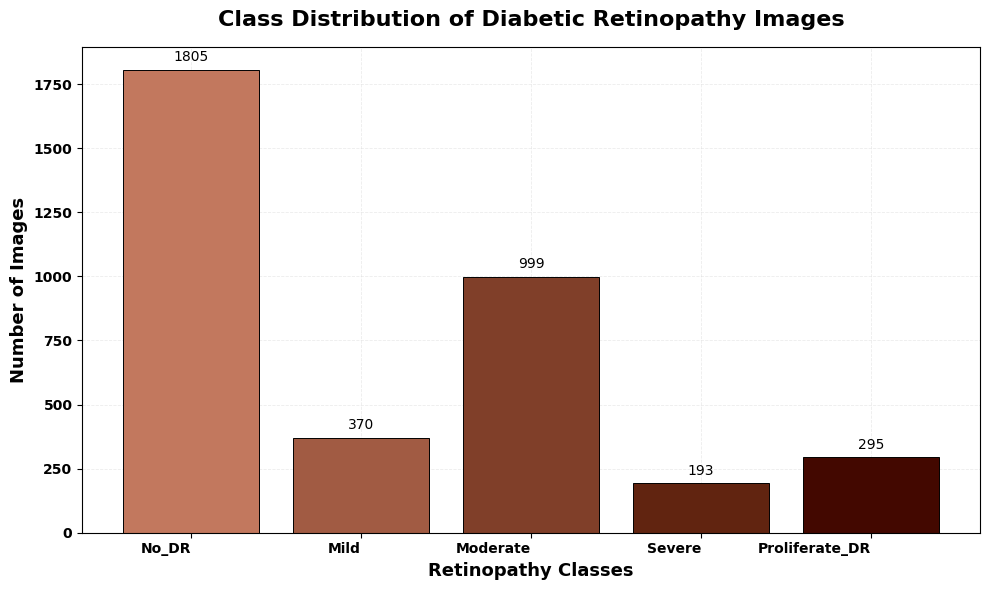

In [ ]:
# Calculate the number of images in each class
class_distribution = image_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)

# Create a figure for the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

# Draw the class-wise image distribution
bars = ax.bar(CLASS_NAMES, class_distribution.values, color=PALETTE, edgecolor="black", linewidth=0.7)

# Add the image count above each bar
ax.bar_label(bars, padding=4, fontsize=10, color=TEXT_COLOR)

# Apply the common plot formatting
format_plot(ax, "Class Distribution of Diabetic Retinopathy Images", "Retinopathy Classes", "Number of Images")

# Rotate class labels for better readability
plt.xticks(rotation=0, ha="right")

# Adjust the plot layout
plt.tight_layout()

# Display the bar chart
plt.show()

The class distribution shows an imbalance across the five severity categories. No_DR has the highest number of images, with 1,805, followed by Moderate with 999, Mild with 370, Proliferate_DR with 295 and Severe with 193. This imbalance may influence model performance and lead to bias towards majority classes. Therefore, class-weighted loss should be considered during model training to improve classification across all severity levels.

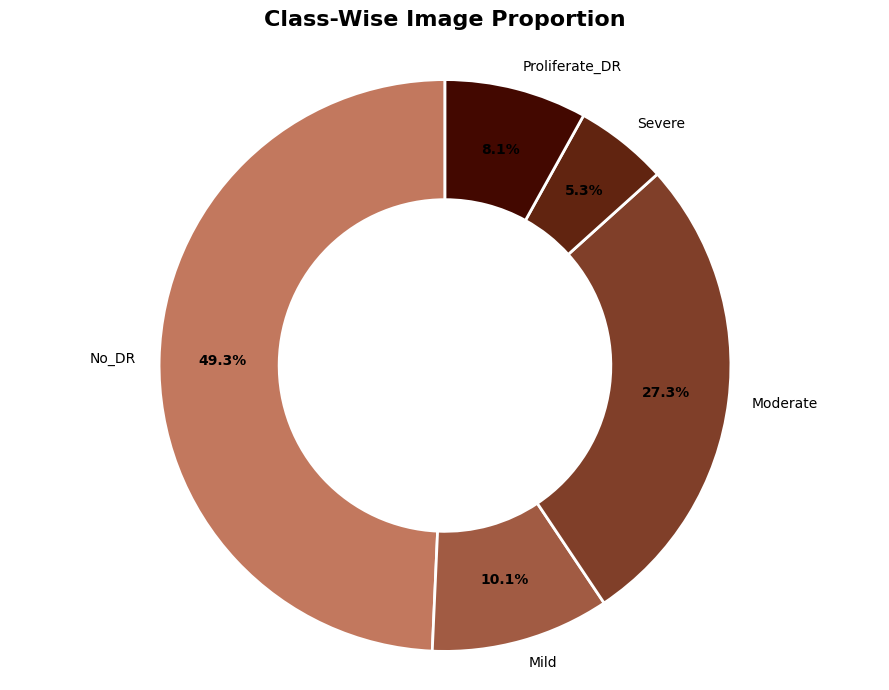

In [ ]:
# Calculate the number of images in each class
class_distribution = image_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)

# Create a figure for the donut chart
fig, ax = plt.subplots(figsize=(9, 7))

# Draw the donut chart with class percentages
wedges, texts, autotexts = ax.pie(class_distribution.values, labels=CLASS_NAMES, autopct="%1.1f%%", startangle=90, colors=PALETTE, pctdistance=0.78, labeldistance=1.08, wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2})

# Format the percentage labels
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight("bold")
    autotext.set_color("black")

# Set the chart title
ax.set_title("Class-Wise Image Proportion", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR, pad=18)

# Keep the chart circular
ax.axis("equal")

# Adjust the plot layout
plt.tight_layout()

# Display the donut chart
plt.show()


The donut chart shows that No_DR accounts for the largest proportion of images at 0.493, followed by Moderate at 0.273. Mild contributes 0.101, while Proliferate_DR and Severe represent 0.81 and 0.53, respectively. The distribution highlights a considerable class imbalance, with Severe having the smallest representation. This may affect model performance, making class-weighted training important for balanced classification.

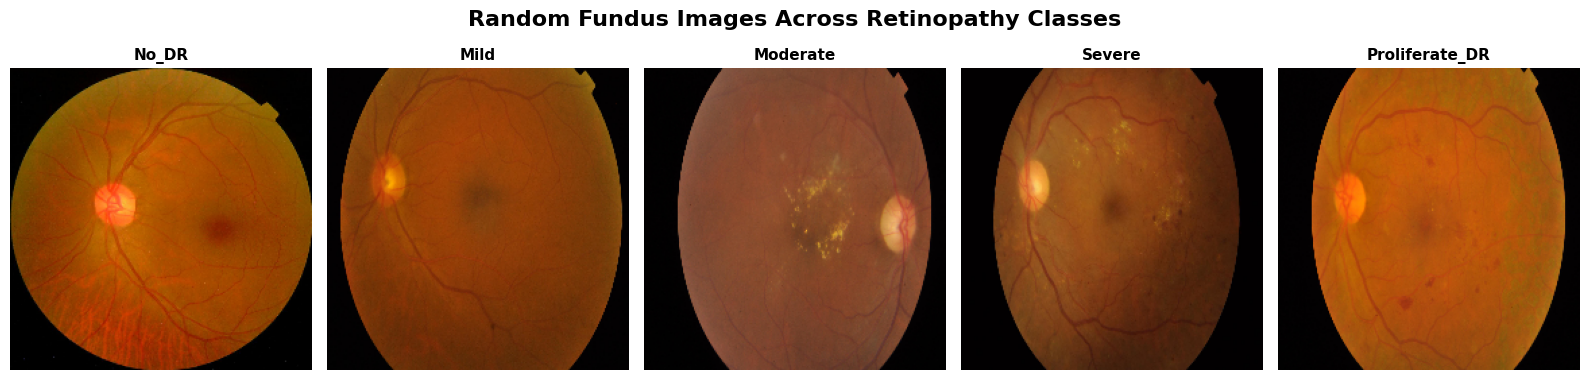

In [ ]:
# Set the number of images to display from each class
IMAGES_PER_CLASS = 1

# Create a figure with one row and five columns
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(16, 4))

# Select and display one random image from each class
for class_index, class_name in enumerate(CLASS_NAMES):

    # Retrieve image paths belonging to the current class
    class_images = image_df.loc[image_df["class_name"] == class_name, "image_path"].tolist()

    # Select one random image
    selected_image = random.choice(class_images)

    # Open and display the selected fundus image
    with Image.open(selected_image) as img:
        axes[class_index].imshow(img.convert("RGB"))

    # Set the image title
    axes[class_index].set_title(class_name, fontsize=11, fontweight="bold", color=TEXT_COLOR)

    # Remove axis ticks
    axes[class_index].axis("off")

# Set the overall figure title
fig.suptitle("Random Fundus Images Across Retinopathy Classes", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)

# Adjust the plot layout
plt.tight_layout()

# Display the image grid
plt.show()

The sample fundus images illustrate visible differences across the five diabetic retinopathy severity classes. No_DR shows a relatively clear retinal structure, while Mild and Moderate exhibit visible retinal abnormalities. Severe and Proliferate_DR images show more prominent changes in retinal appearance.

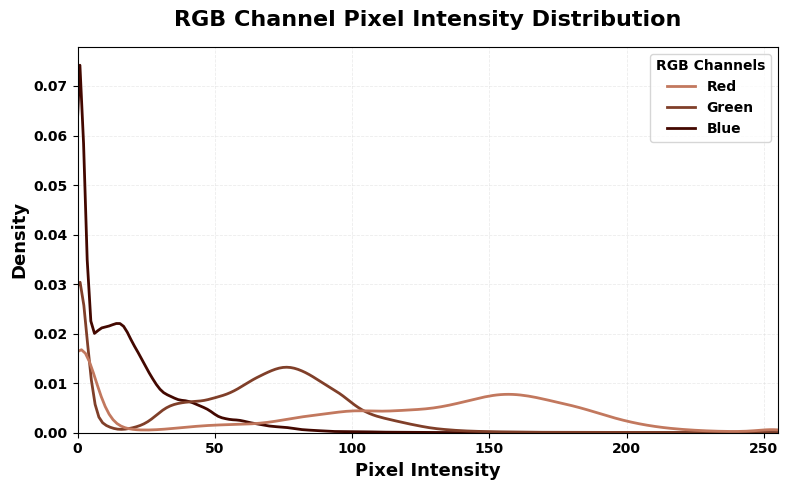

In [ ]:
# Set the number of images for RGB analysis
RGB_SAMPLE_SIZE = min(100, len(image_df))

# Randomly select images from the dataset
rgb_sample_df = image_df.sample(n=RGB_SAMPLE_SIZE, random_state=SEED)

# Create an empty list to store RGB pixel values
rgb_pixel_records = []

# Extract RGB pixel intensities from sampled images
for image_path in rgb_sample_df["image_path"]:

    # Open the image and convert it into RGB format
    with Image.open(image_path) as img:
        rgb_image = img.convert("RGB").resize((128, 128))

        # Convert the image into a NumPy array
        image_array = np.asarray(rgb_image)

        # Store the red channel intensity values
        rgb_pixel_records.extend([{"Channel": "Red", "Intensity": value} for value in image_array[:, :, 0].ravel()[::4]])

        # Store the green channel intensity values
        rgb_pixel_records.extend([{"Channel": "Green", "Intensity": value} for value in image_array[:, :, 1].ravel()[::4]])

        # Store the blue channel intensity values
        rgb_pixel_records.extend([{"Channel": "Blue", "Intensity": value} for value in image_array[:, :, 2].ravel()[::4]])

# Create a DataFrame containing RGB pixel intensities
rgb_distribution_df = pd.DataFrame(rgb_pixel_records)

# Create a figure using the default size
fig, ax = plt.subplots(figsize=FIGURE_SIZE)

# Define the specified palette for the three RGB channels
rgb_palette = {"Red": PALETTE[0], "Green": PALETTE[2], "Blue": PALETTE[4]}

# Draw the RGB pixel intensity distributions
sns.kdeplot(data=rgb_distribution_df, x="Intensity", hue="Channel", hue_order=["Red", "Green", "Blue"], palette=rgb_palette, fill=False, linewidth=2, common_norm=False, ax=ax)

# Apply common plot formatting
format_plot(ax, "RGB Channel Pixel Intensity Distribution", "Pixel Intensity", "Density")

# Set the RGB intensity range
ax.set_xlim(0, 255)

# Format the legend text
legend = ax.get_legend()
if legend:
    legend.set_title("RGB Channels", prop={"weight": "bold", "size": ANNOTATION_SIZE})
    for text in legend.get_texts():
        text.set_fontweight("bold")
        text.set_color(TEXT_COLOR)
        text.set_fontsize(ANNOTATION_SIZE)

# Adjust the plot layout
plt.tight_layout()

# Display the RGB distribution plot
plt.show()

The RGB channel pixel intensity distribution illustrates variations in colour intensity across the fundus images. The blue channel shows a sharp peak at low intensity values, indicating a high concentration of dark pixels. The green channel exhibits a prominent peak around 70–80, while the red channel has a broader distribution with a peak around 150–160.

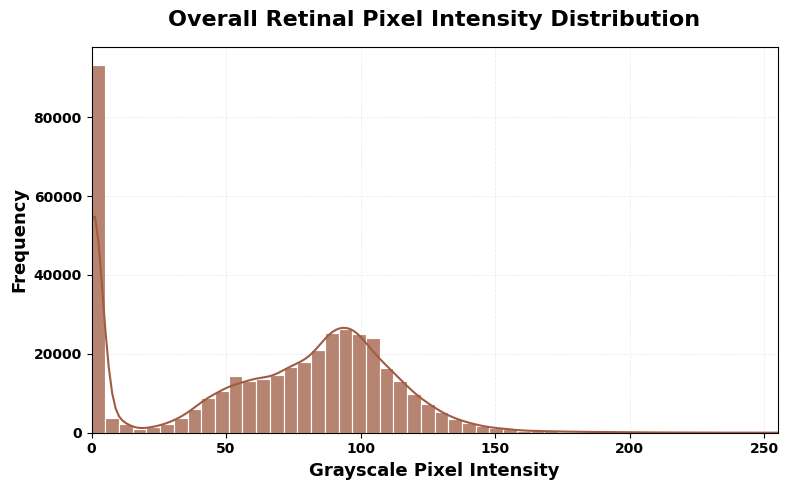

In [ ]:
# Set the number of images for pixel intensity analysis
PIXEL_SAMPLE_SIZE = min(100, len(image_df))

# Randomly select images from the dataset
pixel_sample_df = image_df.sample(n=PIXEL_SAMPLE_SIZE, random_state=SEED)

# Create an empty list to store grayscale pixel values
pixel_intensities = []

# Extract grayscale pixel intensities from sampled images
for image_path in pixel_sample_df["image_path"]:

    # Open the image and convert it into grayscale
    with Image.open(image_path) as img:
        gray_image = img.convert("L").resize((128, 128))

        # Convert the grayscale image into a NumPy array
        gray_array = np.asarray(gray_image)

        # Store the pixel intensity values
        pixel_intensities.extend(gray_array.ravel()[::4])

# Convert the collected intensity values into a NumPy array
pixel_intensities = np.asarray(pixel_intensities)

# Create a figure using the default size
fig, ax = plt.subplots(figsize=FIGURE_SIZE)

# Draw the grayscale intensity histogram with a KDE curve
sns.histplot(pixel_intensities, bins=50, kde=True, color=PALETTE[1], edgecolor="white", alpha=0.75, ax=ax)

# Apply common plot formatting
format_plot(ax, "Overall Retinal Pixel Intensity Distribution", "Grayscale Pixel Intensity", "Frequency")

# Set the pixel intensity range
ax.set_xlim(0, 255)

# Adjust the plot layout
plt.tight_layout()

# Display the pixel intensity plot
plt.show()

give observations in short
The overall retinal pixel intensity distribution shows a sharp peak near zero, indicating a large number of dark pixels. Most remaining pixel intensities are concentrated between 50 and 120, with the highest frequency around 90–100. The distribution gradually decreases at higher intensity levels, indicating fewer bright pixels in the fundus images.

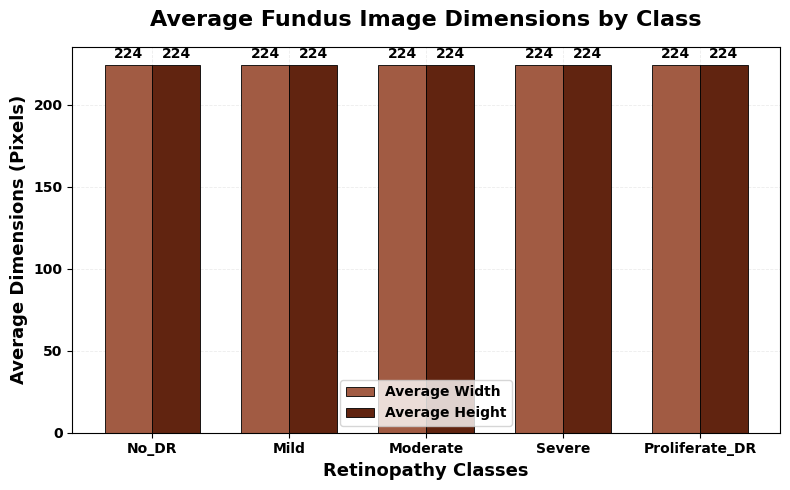

In [ ]:
# Calculate the average image width and height for each class
dimension_summary = image_stats_df.groupby("class_name")[["width", "height"]].mean().reindex(CLASS_NAMES)

# Create the class positions for the grouped bars
x_positions = np.arange(NUM_CLASSES)

# Set the width of each bar
bar_width = 0.35

# Create a figure using the default size
fig, ax = plt.subplots(figsize=FIGURE_SIZE)

# Draw bars representing average image width
width_bars = ax.bar(x_positions - bar_width / 2, dimension_summary["width"], width=bar_width, color=PALETTE[1], edgecolor="black", linewidth=0.6, label="Average Width")

# Draw bars representing average image height
height_bars = ax.bar(x_positions + bar_width / 2, dimension_summary["height"], width=bar_width, color=PALETTE[3], edgecolor="black", linewidth=0.6, label="Average Height")

# Add bold grey annotations above the width bars
ax.bar_label(width_bars, fmt="%.0f", padding=3, fontsize=ANNOTATION_SIZE, fontweight="bold", color=TEXT_COLOR)

# Add bold grey annotations above the height bars
ax.bar_label(height_bars, fmt="%.0f", padding=3, fontsize=ANNOTATION_SIZE, fontweight="bold", color=TEXT_COLOR)

# Set the class names as X-axis labels
ax.set_xticks(x_positions)
ax.set_xticklabels(CLASS_NAMES)

# Apply common plot formatting
format_plot(ax, "Average Fundus Image Dimensions by Class", "Retinopathy Classes", "Average Dimensions (Pixels)")

# Add a bold grey legend
legend = ax.legend(fontsize=ANNOTATION_SIZE)
for text in legend.get_texts():
    text.set_fontweight("bold")
    text.set_color(TEXT_COLOR)

# Adjust the plot layout
plt.tight_layout()

# Display the image dimension comparison
plt.show()


The average fundus image dimensions are consistent across all five retinopathy classes. Both width and height are 224 pixels for every class, confirming that all images have been resized to a uniform 224 × 224 resolution for model training and evaluation.

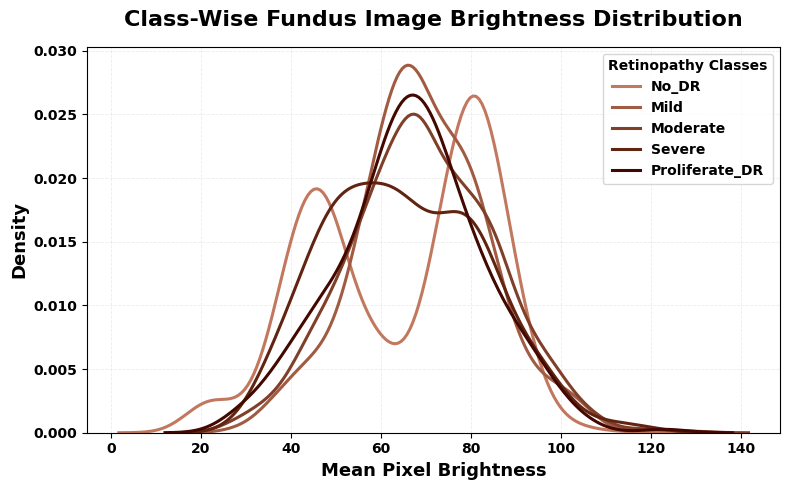

In [ ]:
# Create a copy of the image statistics
brightness_df = image_stats_df.copy()

# Calculate brightness using the standard luminance formula
brightness_df["brightness"] = 0.299 * brightness_df["red_mean"] + 0.587 * brightness_df["green_mean"] + 0.114 * brightness_df["blue_mean"]

# Remove records containing missing brightness values
brightness_df = brightness_df.dropna(subset=["brightness"])

# Create a figure using the default size
fig, ax = plt.subplots(figsize=FIGURE_SIZE)

# Draw KDE curves for the five retinopathy classes
for index, class_name in enumerate(CLASS_NAMES):

    # Select brightness values belonging to the current class
    class_brightness = brightness_df.loc[brightness_df["class_name"] == class_name, "brightness"]

    # Plot the brightness distribution for the current class
    sns.kdeplot(data=class_brightness, color=PALETTE[index], linewidth=2.2, fill=False, label=class_name, ax=ax)

# Apply common plot formatting
format_plot(ax, "Class-Wise Fundus Image Brightness Distribution", "Mean Pixel Brightness", "Density")

# Add a legend to identify the five classes
legend = ax.legend(title="Retinopathy Classes", fontsize=ANNOTATION_SIZE)

# Format the legend text
for text in legend.get_texts():
    text.set_fontweight("bold")
    text.set_color(TEXT_COLOR)

# Format the legend title
legend.get_title().set_fontweight("bold")
legend.get_title().set_color(TEXT_COLOR)

# Adjust the plot layout
plt.tight_layout()

# Display the brightness distribution
plt.show()

The brightness distributions vary across the five retinopathy classes. No_DR images show a bimodal pattern with peaks around 45 and 80, while the other classes mainly peak between 60 and 75. The distributions overlap considerably, indicating similarities in brightness characteristics across classes.

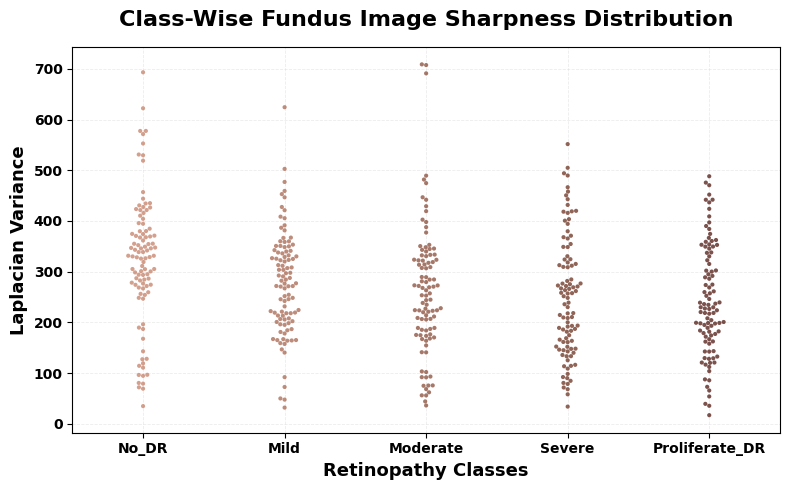

In [ ]:
# Set the maximum number of images to sample from each class
SHARPNESS_SAMPLE_SIZE = 100

# Create an empty list to store sharpness measurements
sharpness_records = []

# Calculate sharpness for a random sample from each class
for class_name in CLASS_NAMES:

    # Retrieve image paths belonging to the current class
    class_images = image_df.loc[image_df["class_name"] == class_name, "image_path"].tolist()

    # Select random images without replacement
    selected_images = random.sample(class_images, min(SHARPNESS_SAMPLE_SIZE, len(class_images)))

    # Calculate sharpness for each selected image
    for image_path in selected_images:

        # Read the fundus image using OpenCV
        image = cv2.imread(image_path)

        # Skip the image if it cannot be loaded
        if image is None:
            continue

        # Convert the image into grayscale
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Resize the image to a standard resolution
        gray_image = cv2.resize(gray_image, (224, 224), interpolation=cv2.INTER_AREA)

        # Calculate image sharpness using Laplacian variance
        sharpness_score = cv2.Laplacian(gray_image, cv2.CV_64F).var()

        # Store the class name and sharpness score
        sharpness_records.append({"class_name": class_name, "sharpness": sharpness_score})

# Create a DataFrame containing the sharpness measurements
sharpness_df = pd.DataFrame(sharpness_records)
# Create a figure using the default size
fig, ax = plt.subplots(figsize=FIGURE_SIZE)

# Draw individual sharpness measurements using a swarm plot
sns.swarmplot(data=sharpness_df, x="class_name", y="sharpness", order=CLASS_NAMES, hue="class_name", hue_order=CLASS_NAMES, palette=dict(zip(CLASS_NAMES, PALETTE)), size=3, alpha=0.7, legend=False, ax=ax)

# Apply common plot formatting
format_plot(ax, "Class-Wise Fundus Image Sharpness Distribution", "Retinopathy Classes", "Laplacian Variance")

# Keep the class labels horizontal
plt.xticks(rotation=0)

# Adjust the plot layout
plt.tight_layout()

# Display the sharpness distribution
plt.show()

The sharpness distribution shows variation across all five retinopathy classes. No_DR images exhibit the widest range of Laplacian variance, including some highly sharp outliers. Mild, Moderate and Severe classes show broadly overlapping sharpness values, while Proliferate_DR images are more concentrated at lower values.

## **Image Preprocessing**

### **Image Validation**


The image validation stage ensures that the dataset contains readable images with correct class assignments. It also identifies duplicate images using file hashing. This helps prevent data leakage and improves dataset reliability before model training.

In [ ]:
# Create a copy of the existing image metadata
preprocessing_df = image_df.copy()

# Create empty lists to store validation results
valid_image_paths = []
corrupted_image_paths = []
invalid_label_paths = []
duplicate_records = []

# Create a dictionary to store image hashes
image_hashes = {}

In [ ]:
# Validate every image in the dataset
for _, row in preprocessing_df.iterrows():

    # Retrieve the image path and its assigned class
    image_path = row["image_path"]
    class_name = row["class_name"]

    # Check whether the assigned class belongs to the configured classes
    if class_name not in CLASS_NAMES:
        invalid_label_paths.append(image_path)
        continue

    # Verify that the image file exists
    if not os.path.isfile(image_path):
        corrupted_image_paths.append(image_path)
        continue

    try:
        # Open the image and verify its contents
        with Image.open(image_path) as img:
            img.verify()

        # Reopen the image and check whether its pixels are readable
        with Image.open(image_path) as img:
            img.load()

        # Add the successfully validated image path
        valid_image_paths.append(image_path)

        # Calculate the SHA-256 hash of the image file
        with open(image_path, "rb") as file:
            image_hash = hashlib.sha256(file.read()).hexdigest()

        # Check whether the same image hash already exists
        if image_hash in image_hashes:
            duplicate_records.append({"image_path": image_path, "duplicate_of": image_hashes[image_hash], "class_name": class_name})
        else:
            image_hashes[image_hash] = image_path
    except Exception:
        # Store the path of an unreadable or corrupted image
        corrupted_image_paths.append(image_path)

In [ ]:
# Retain only readable images with valid class labels
preprocessing_df = preprocessing_df[preprocessing_df["image_path"].isin(valid_image_paths)].copy()

# Remove exact duplicate files while retaining the first occurrence
duplicate_paths = [record["image_path"] for record in duplicate_records]
preprocessing_df = preprocessing_df[~preprocessing_df["image_path"].isin(duplicate_paths)].reset_index(drop=True)

# Create a DataFrame containing duplicate image information
duplicate_df = pd.DataFrame(duplicate_records)

In [ ]:
# Display the image validation summary
print("Image Validation Summary")
print("-" * 45)
print("Total images before validation:", len(image_df))
print("Valid images:", len(valid_image_paths))
print("Corrupted or unreadable images:", len(corrupted_image_paths))
print("Invalid class labels:", len(invalid_label_paths))
print("Exact duplicate images:", len(duplicate_records))
print("Images after validation:", len(preprocessing_df))

# Display the final class distribution
print("Class Distribution After Validation")
print("-" * 45)
print(preprocessing_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))

# Display duplicate image records when available
if not duplicate_df.empty:
    display(duplicate_df.head())
else:
    print("No exact duplicate images detected.")


Image Validation Summary
---------------------------------------------
Total images before validation: 3662
Valid images: 3662
Corrupted or unreadable images: 0
Invalid class labels: 0
Exact duplicate images: 128
Images after validation: 3534
Class Distribution After Validation
---------------------------------------------
class_name
No_DR             1800
Mild               344
Moderate           939
Severe             180
Proliferate_DR     271
Name: count, dtype: int64


,image_path,duplicate_of,class_name
0,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
1,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
2,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
3,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR
4,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,/kaggle/input/datasets/dokkuvenkatalakshmi/dia...,No_DR


### **CLAHE**



Contrast Limited Adaptive Histogram Equalisation (CLAHE) is used to improve local contrast in retinal fundus images. It enhances details in regions that may appear too dark or have low contrast.

In [ ]:
# Define the CLAHE enhancement parameters
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID_SIZE = (8, 8)

# Create a CLAHE object for local contrast enhancement
clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID_SIZE)

In [ ]:
# Define a function to enhance fundus image contrast
def apply_clahe(image):

    # Convert the RGB image into LAB colour space
    lab_image = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

    # Separate the luminance and colour channels
    luminance, channel_a, channel_b = cv2.split(lab_image)

    # Apply CLAHE to the luminance channel
    enhanced_luminance = clahe.apply(luminance)

    # Merge the enhanced luminance with the original colour channels
    enhanced_lab = cv2.merge((enhanced_luminance, channel_a, channel_b))

    # Convert the enhanced LAB image back to RGB colour space
    enhanced_image = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)

    # Return the contrast-enhanced image
    return enhanced_image

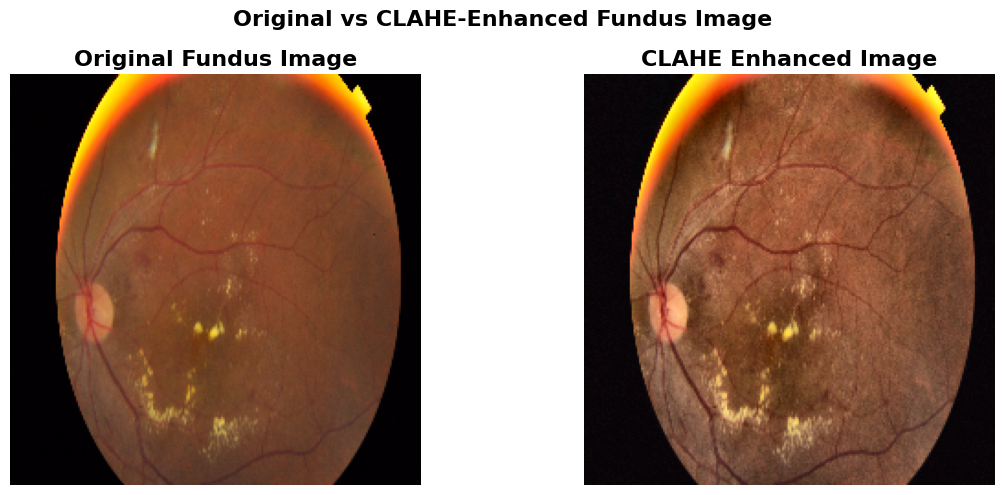

In [ ]:
# Select one random image from the validated dataset
selected_image = random.choice(preprocessing_df["image_path"].tolist())

# Load the original fundus image in RGB format
with Image.open(selected_image) as img:
    original_image = np.asarray(img.convert("RGB"))

# Apply CLAHE contrast enhancement
enhanced_image = apply_clahe(original_image)

# Create a figure with two comparison panels
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Display the original fundus image
axes[0].imshow(original_image)
axes[0].set_title("Original Fundus Image", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[0].axis("off")

# Display the CLAHE-enhanced fundus image
axes[1].imshow(enhanced_image)
axes[1].set_title("CLAHE Enhanced Image", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[1].axis("off")

# Set the overall figure title
fig.suptitle("Original vs CLAHE-Enhanced Fundus Image", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)

# Adjust the plot layout
plt.tight_layout()

# Display the image comparison
plt.show()

CLAHE enhancement improves local contrast, making retinal blood vessels, fine details and bright lesions more visible for better feature extraction and classification.

### **Image Denoising**

In [ ]:
# Define the Non-Local Means denoising parameters
NLM_FILTER_STRENGTH = 5
NLM_TEMPLATE_WINDOW_SIZE = 7
NLM_SEARCH_WINDOW_SIZE = 21

# Define a function to reduce noise in fundus images
def apply_nlm_denoising(image):

    # Apply Non-Local Means denoising to the RGB image
    denoised_image = cv2.fastNlMeansDenoisingColored(image, None, NLM_FILTER_STRENGTH, NLM_FILTER_STRENGTH, NLM_TEMPLATE_WINDOW_SIZE, NLM_SEARCH_WINDOW_SIZE)

    # Return the denoised image
    return denoised_image

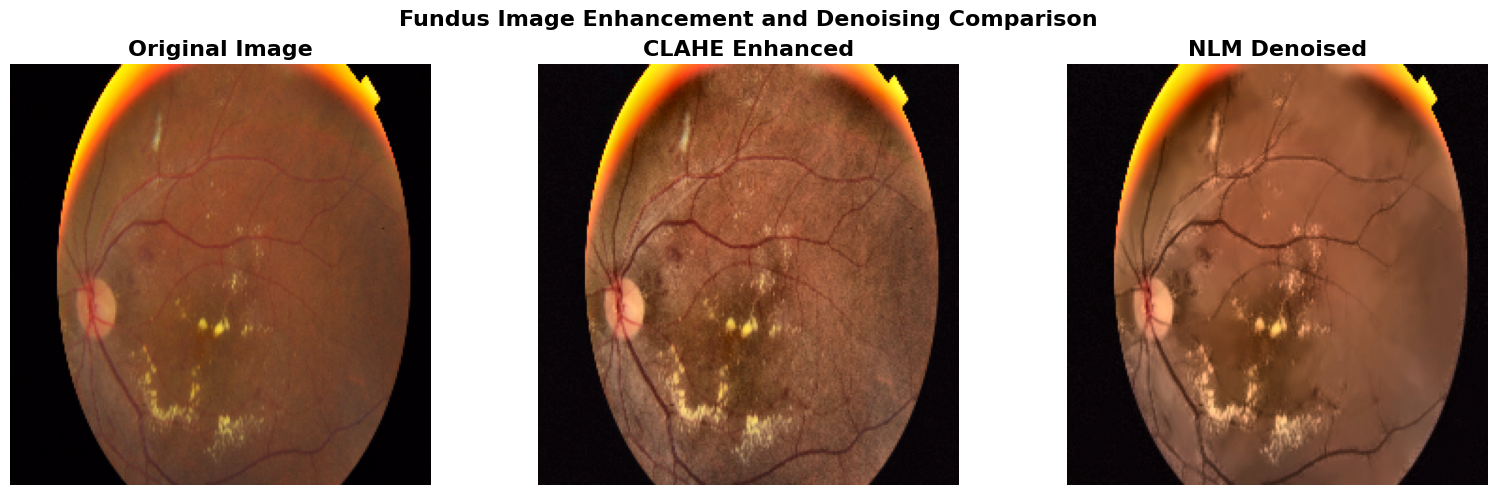

In [ ]:
# Apply Non-Local Means denoising to the CLAHE-enhanced image
denoised_image = apply_nlm_denoising(enhanced_image)

# Create a figure with three comparison panels
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Display the original fundus image
axes[0].imshow(original_image)
axes[0].set_title("Original Image", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[0].axis("off")

# Display the CLAHE-enhanced image
axes[1].imshow(enhanced_image)
axes[1].set_title("CLAHE Enhanced", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[1].axis("off")

# Display the denoised image
axes[2].imshow(denoised_image)
axes[2].set_title("NLM Denoised", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[2].axis("off")

# Set the overall figure title
fig.suptitle("Fundus Image Enhancement and Denoising Comparison", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)

# Adjust the plot layout
plt.tight_layout()

# Display the preprocessing comparison
plt.show()

The CLAHE-enhanced image improves retinal contrast and visibility of blood vessels and lesions, while NLM denoising reduces unwanted noise and produces a smoother appearance while preserving important retinal structures.

### **Image Resizing**

In [ ]:
# Define the target image dimensions
RESIZE_DIMENSIONS = (IMAGE_SIZE, IMAGE_SIZE)

# Define a function to resize fundus images
def resize_image(image):

    # Resize the image using area interpolation
    resized_image = cv2.resize(image, RESIZE_DIMENSIONS, interpolation=cv2.INTER_AREA)

    # Return the resized image
    return resized_image

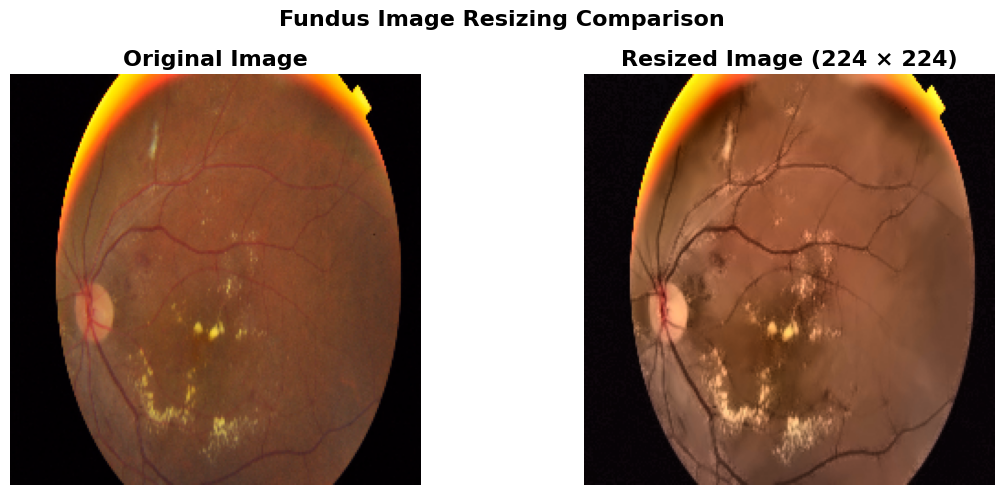

Original image dimensions: (224, 224, 3)
Resized image dimensions: (224, 224, 3)


In [ ]:

# Resize the CLAHE-enhanced and denoised image
resized_image = resize_image(denoised_image)

# Create a figure with two comparison panels
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Display the original fundus image
axes[0].imshow(original_image)
axes[0].set_title("Original Image", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[0].axis("off")

# Display the resized and preprocessed image
axes[1].imshow(resized_image)
axes[1].set_title(f"Resized Image ({IMAGE_SIZE} × {IMAGE_SIZE})", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[1].axis("off")

# Set the overall figure title
fig.suptitle("Fundus Image Resizing Comparison", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)

# Adjust the plot layout
plt.tight_layout()

# Display the resizing comparison
plt.show()

# Display the original and resized image dimensions
print("Original image dimensions:", original_image.shape)
print("Resized image dimensions:", resized_image.shape)

The original fundus image is resized to 224 × 224 pixels, while preserving key retinal features such as blood vessels, the optic disc and visible lesions for deep learning analysis.

### **Image Normalisation**

In [ ]:
# Define the ImageNet RGB channel means
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)

# Define the ImageNet RGB channel standard deviations
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# Define a function to normalise fundus images
def normalize_image(image):
    # Convert image pixel values to float32 and scale them to the range 0 to 1
    image = image.astype(np.float32) / 255.0
    # Apply ImageNet channel-wise normalisation
    normalized_image = (image - IMAGENET_MEAN) / IMAGENET_STD
    # Return the normalised image
    return normalized_image

In [ ]:
# Apply ImageNet normalisation to the resized image
normalized_image = normalize_image(resized_image)

# Display the normalised image properties
print("Normalised image shape:", normalized_image.shape)
print("Normalised image data type:", normalized_image.dtype)
print("Normalised pixel minimum:", normalized_image.min())
print("Normalised pixel maximum:", normalized_image.max())
print("Normalised image mean:", normalized_image.mean())

Normalised image shape: (224, 224, 3)
Normalised image data type: float32
Normalised pixel minimum: -2.0665298
Normalised pixel maximum: 2.4110641
Normalised image mean: -0.76122737


### **Data Augmentation**

In [ ]:
# Define the maximum image rotation angle
ROTATION_RANGE = 10

# Define the probability of applying horizontal flipping
HORIZONTAL_FLIP_PROBABILITY = 0.5

# Define the brightness variation range
BRIGHTNESS_RANGE = (0.9, 1.1)

In [ ]:
# Define a function to augment fundus images
def augment_image(image):

    # Retrieve the image dimensions
    height, width = image.shape[:2]

    # Generate a random rotation angle
    rotation_angle = random.uniform(-ROTATION_RANGE, ROTATION_RANGE)

    # Create the rotation transformation matrix
    rotation_matrix = cv2.getRotationMatrix2D((width / 2, height / 2), rotation_angle, 1.0)

    # Apply a small rotation while preserving image dimensions
    augmented_image = cv2.warpAffine(image, rotation_matrix, (width, height), borderMode=cv2.BORDER_REFLECT_101)

    # Randomly apply horizontal flipping
    if random.random() < HORIZONTAL_FLIP_PROBABILITY:
        augmented_image = cv2.flip(augmented_image, 1)

    # Generate a random brightness adjustment factor
    brightness_factor = random.uniform(BRIGHTNESS_RANGE[0], BRIGHTNESS_RANGE[1])

    # Apply brightness variation and keep pixel values within the valid range
    augmented_image = np.clip(augmented_image.astype(np.float32) * brightness_factor, 0, 255).astype(np.uint8)

    # Return the augmented image
    return augmented_image

In [ ]:
# Apply augmentation to the resized sample image
augmented_image = augment_image(resized_image)

# Display the augmentation output properties
print("Original image shape:", resized_image.shape)
print("Augmented image shape:", augmented_image.shape)
print("Augmented image data type:", augmented_image.dtype)
print("Augmented pixel minimum:", augmented_image.min())
print("Augmented pixel maximum:", augmented_image.max())

Original image shape: (224, 224, 3)
Augmented image shape: (224, 224, 3)
Augmented image data type: uint8
Augmented pixel minimum: 0
Augmented pixel maximum: 241


### **Dataset Splitting**

In [ ]:
# Define the random seed for reproducible dataset splitting
SPLIT_RANDOM_STATE = SEED

# Separate 70% training data and 30% temporary data
train_df, temporary_df = train_test_split(preprocessing_df, test_size=0.30, stratify=preprocessing_df["class_name"], random_state=SPLIT_RANDOM_STATE)

# Divide the temporary data equally into validation and testing sets
validation_df, test_df = train_test_split(temporary_df, test_size=0.50, stratify=temporary_df["class_name"], random_state=SPLIT_RANDOM_STATE)

# Reset the indices of all three datasets
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

In [ ]:

# Display the number of images in each subset
print("Dataset Splitting Summary")
print("-" * 45)
print("Total validated images:", len(preprocessing_df))
print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Testing images:", len(test_df))

# Calculate the percentage of images in each subset
print("Dataset Split Percentages")
print("-" * 45)
print(f"Training: {len(train_df) / len(preprocessing_df) * 100:.2f}%")
print(f"Validation: {len(validation_df) / len(preprocessing_df) * 100:.2f}%")
print(f"Testing: {len(test_df) / len(preprocessing_df) * 100:.2f}%")

# Compare class distributions across all three subsets
split_distribution = pd.DataFrame({"Training": train_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0), "Validation": validation_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0), "Testing": test_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)})

# Display the class-wise distribution
print("Class Wise Distribution")
display(split_distribution)

# Verify that the image paths do not overlap between subsets
train_paths = set(train_df["image_path"])
validation_paths = set(validation_df["image_path"])
test_paths = set(test_df["image_path"])

# Check for data leakage between the three subsets
print("Data Leakage Verification")
print("-" * 45)
print("Training and validation overlap:", len(train_paths.intersection(validation_paths)))
print("Training and testing overlap:", len(train_paths.intersection(test_paths)))
print("Validation and testing overlap:", len(validation_paths.intersection(test_paths)))

# Verify that all three subsets contain the expected class labels
print("Training classes:", sorted(train_df["class_name"].unique()))
print("Validation classes:", sorted(validation_df["class_name"].unique()))
print("Testing classes:", sorted(test_df["class_name"].unique()))


Dataset Splitting Summary
---------------------------------------------
Total validated images: 3534
Training images: 2473
Validation images: 530
Testing images: 531
Dataset Split Percentages
---------------------------------------------
Training: 69.98%
Validation: 15.00%
Testing: 15.03%
Class Wise Distribution


,Training,Validation,Testing
class_name,,,
No_DR,1259,270,271
Mild,241,51,52
Moderate,657,141,141
Severe,126,27,27
Proliferate_DR,190,41,40


Data Leakage Verification
---------------------------------------------
Training and validation overlap: 0
Training and testing overlap: 0
Validation and testing overlap: 0
Training classes: ['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']
Validation classes: ['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']
Testing classes: ['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']


### **Image Preprocessing Pipeline**

In [ ]:
# Define the batch size for model training
BATCH_SIZE = 32

# Create a mapping between class names and integer labels
CLASS_TO_INDEX = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}

In [ ]:
def preprocess_numpy(image_path, label, training=False):

    # Convert inputs to NumPy-compatible values
    if tf.is_tensor(image_path):
        image_path = image_path.numpy()
    if tf.is_tensor(label):
        label = label.numpy()

    # Decode image path
    image_path = image_path.decode("utf-8")

    # Read image
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Apply preprocessing
    image = apply_clahe(image)
    image = apply_nlm_denoising(image)
    image = resize_image(image)

    # Apply augmentation only during training
    if training:
        image = augment_image(image)

    # Normalise image
    image = normalize_image(image)

    # Convert TensorFlow tensor to NumPy array if necessary
    if tf.is_tensor(image):
        image = image.numpy()

    # Ensure correct output types
    image = np.asarray(image, dtype=np.float32)
    label = np.asarray(label).item()
    return image, np.int32(label)

In [ ]:
# Define a function to create a TensorFlow dataset
def create_image_dataset(dataframe, training=False):
    # Retrieve image paths from the supplied dataframe
    image_paths = dataframe["image_path"].values

    # Convert class names into integer labels
    image_labels = dataframe["class_name"].map(CLASS_TO_INDEX).values.astype(np.int32)

    # Create a TensorFlow dataset from image paths and labels
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, image_labels))

    # Shuffle the training dataset
    if training:
        dataset = dataset.shuffle(len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    # Define the image preprocessing operation
    def process_sample(image_path, label):
        # Apply the preprocessing function using NumPy
        image, label = tf.numpy_function(func=lambda path, target: preprocess_numpy(path, target, training), inp=[image_path, label], Tout=[tf.float32, tf.int32])

        # Set the image and label shapes explicitly
        image.set_shape((IMAGE_SIZE, IMAGE_SIZE, IMAGE_CHANNELS))
        label.set_shape(())

        # Return the processed image and its label
        return image, label

    # Apply preprocessing to the dataset
    dataset = dataset.map(process_sample, num_parallel_calls=tf.data.AUTOTUNE)

    # Group images into batches
    dataset = dataset.batch(BATCH_SIZE)

    # Prefetch batches to improve data loading efficiency
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    # Return the prepared dataset
    return dataset

In [ ]:
# Create the training dataset with augmentation enabled
train_dataset = create_image_dataset(train_df, training=True)

# Create the validation dataset without augmentation
validation_dataset = create_image_dataset(validation_df, training=False)

# Create the testing dataset without augmentation
test_dataset = create_image_dataset(test_df, training=False)

In [ ]:
# Retrieve one batch from the training dataset
train_images, train_labels = next(iter(train_dataset))

# Retrieve one batch from the validation dataset
validation_images, validation_labels = next(iter(validation_dataset))

# Retrieve one batch from the testing dataset
test_images, test_labels = next(iter(test_dataset))

# Display the training batch properties
print("Training Dataset")
print("-" * 40)
print("Image batch shape:", train_images.shape)
print("Label batch shape:", train_labels.shape)
print("Image data type:", train_images.dtype)

# Display the validation batch properties
print("Validation Datset")
print("-" * 40)
print("Image batch shape:", validation_images.shape)
print("Label batch shape:", validation_labels.shape)

# Display the testing batch properties
print("Testing Dataset")
print("-" * 40)
print("Image batch shape:", test_images.shape)
print("Label batch shape:", test_labels.shape)

# Display the total number of batches in each dataset
print("Total Dataset Batches")
print("-" * 40)
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

# Verify that the preprocessed image dimensions are correct
print("Image Preprocessing Verification")
print("-" * 40)
print("Expected image shape:", (IMAGE_SIZE, IMAGE_SIZE, IMAGE_CHANNELS))
print("Actual image shape:", tuple(train_images.shape[1:]))
print("Normalised pixel values are finite:", np.isfinite(train_images.numpy()).all())


Training Dataset
----------------------------------------
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Validation Datset
----------------------------------------
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Testing Dataset
----------------------------------------
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Total Dataset Batches
----------------------------------------
Training batches: 78
Validation batches: 17
Testing batches: 17
Image Preprocessing Verification
----------------------------------------
Expected image shape: (224, 224, 3)
Actual image shape: (224, 224, 3)
Normalised pixel values are finite: True


## **Deep Learning Models**

### **Vision Transformer (ViT)**



The Vision Transformer divides fundus images into fixed-size patches and converts them into patch embeddings. Transformer encoder blocks use multi-head self-attention and feed-forward networks to learn relationships between retinal regions. A classification head produces predictions for the five diabetic retinopathy severity levels.

In [ ]:
# Calculate the number of training samples belonging to each severity class.
class_counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)

# Calculate the total number of samples in the training dataset.
total_samples = len(train_df)

# Calculate class weights to handle class imbalance during model training.
class_weight_dict = {CLASS_TO_INDEX[class_name]: total_samples / (NUM_CLASSES * count) for class_name, count in class_counts.items() if count > 0}

# Display the calculated class weights for each severity class.
print("Class weights:", class_weight_dict)

Class weights: {0: 0.39285146942017474, 1: 2.0522821576763484, 2: 0.7528158295281583, 3: 3.925396825396825, 4: 2.603157894736842}


In [ ]:
# Define the ImageNet mean values for RGB channel normalisation.
IMAGENET_MEAN = tf.constant([0.485, 0.456, 0.406], dtype=tf.float32)

# Define the ImageNet standard deviation values for RGB channel normalisation.
IMAGENET_STD = tf.constant([0.229, 0.224, 0.225], dtype=tf.float32)

# Define a function to restore normalised images to their original RGB pixel range.
def restore_image_range(image, label):
    # Reverse ImageNet normalisation to restore pixel values to the 0–255 range.
    image = (image * IMAGENET_STD + IMAGENET_MEAN) * 255.0
    image = tf.clip_by_value(image, 0.0, 255.0)

    # Return the restored image along with its corresponding label.
    return image, label

In [ ]:
# Prepare the training dataset by restoring image values, batching and prefetching.
vit_train_dataset = train_dataset.unbatch().map(restore_image_range, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Prepare the validation dataset by restoring image values, batching and prefetching.
vit_validation_dataset = validation_dataset.unbatch().map(restore_image_range, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Prepare the test dataset by restoring image values, batching and prefetching.
vit_test_dataset = test_dataset.unbatch().map(restore_image_range, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
# Pretrained Vision Transformer configuration
VIT_PRESET = "vit_base_patch16_224_imagenet"

# Load ImageNet-pretrained ViT backbone
vit_backbone = keras_hub.models.ViTBackbone.from_preset(VIT_PRESET)

# Load matching preprocessing configuration
vit_preprocessor = (keras_hub.models.ViTImageClassifierPreprocessor.from_preset(VIT_PRESET))

# Build five-class Vision Transformer classifier
vit_model = keras_hub.models.ViTImageClassifier(backbone=vit_backbone, num_classes=NUM_CLASSES,preprocessor=vit_preprocessor,pooling="token",dropout=0.2,activation="softmax")

# Enable fine-tuning of pretrained weights
vit_model.backbone.trainable = True

# Display model architecture
vit_model.summary()

Preprocessor: "vi_t_image_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ vi_t_image_converter (ViTImageConverter)                      │                   Image size: (224, 224) │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "vi_t_image_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                  ┃ Output Shape                       ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer)                           │ (None, 224, 224, 3)                │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ vi_t_backbone (ViTBackbone)                   │ (None, 197, 768)                   │          85,798,656 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ get_item (GetItem)                            │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ output_dropout (Dropout)                      │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ predictions (Dense)                           │ (None, 5)                          │               3,845 │
└───────────────────────────────────────────────┴────────────────────────────────────┴─────────────────────┘

 Total params: 85,802,501 (327.31 MB)

 Trainable params: 85,802,501 (327.31 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the ViT model using the Adam optimiser, sparse categorical cross-entropy loss and accuracy metric.
vit_model.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-5),loss=keras.losses.SparseCategoricalCrossentropy(),metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])

In [ ]:
# Define callbacks to save the best ViT model and adjust the learning rate during training.
vit_callbacks = [
    # Save the model whenever the validation loss reaches a new minimum.
    keras.callbacks.ModelCheckpoint("best_vit_model.keras", monitor="val_loss", save_best_only=True, mode="min", verbose=1),

    # Reduce the learning rate by 80% when the validation loss does not improve for three consecutive epochs.
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, min_lr=1e-7, verbose=1)
]

In [ ]:
# Train the ViT model using the training dataset and validate its performance after each epoch.
vit_history = vit_model.fit(vit_train_dataset, validation_data=vit_validation_dataset, epochs=8, class_weight=class_weight_dict, callbacks=vit_callbacks, verbose=1)

Epoch 1/8
     78/Unknown 309s 3s/step - accuracy: 0.4287 - loss: 1.6587
Epoch 1: val_loss improved from None to 0.88153, saving model to best_vit_model.keras

Epoch 1: finished saving model to best_vit_model.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 357s 4s/step - accuracy: 0.5374 - loss: 1.4392 - val_accuracy: 0.6340 - val_loss: 0.8815 - learning_rate: 2.0000e-05
Epoch 2/8
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6895 - loss: 1.0296
Epoch 2: val_loss improved from 0.88153 to 0.70982, saving model to best_vit_model.keras

Epoch 2: finished saving model to best_vit_model.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 307s 4s/step - accuracy: 0.7173 - loss: 0.9689 - val_accuracy: 0.7264 - val_loss: 0.7098 - learning_rate: 2.0000e-05
Epoch 3/8
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7509 - loss: 0.8059
Epoch 3: val_loss did not improve from 0.70982
78/78 ━━━━━━━━━━━━━━━━━━━━ 304s 4s/step - accuracy: 0.7667 - loss: 0.8062 - val_accuracy: 0.7113 - val_loss: 0.7408 - learning_rate: 2.0000e-

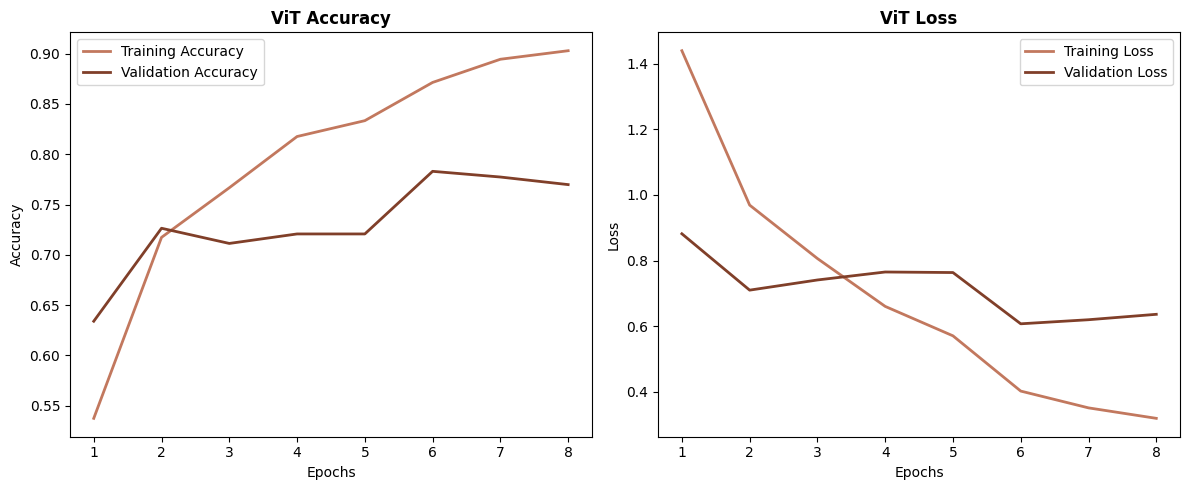

In [ ]:
# Generate the epoch range based on the total number of training epochs.
epochs = range(1, len(vit_history.history["accuracy"]) + 1)

# Create two subplots to display training and validation accuracy and loss side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot training and validation accuracy.
axes[0].plot(epochs, vit_history.history["accuracy"], label="Training Accuracy", color=PALETTE[0], linewidth=2)
axes[0].plot(epochs, vit_history.history["val_accuracy"], label="Validation Accuracy", color=PALETTE[2], linewidth=2)

# Set the title, axis labels and legend for the accuracy plot.
axes[0].set_title("ViT Accuracy", fontweight="bold", color=TEXT_COLOR)
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Plot training and validation loss.
axes[1].plot(epochs, vit_history.history["loss"], label="Training Loss", color=PALETTE[0], linewidth=2)
axes[1].plot(epochs, vit_history.history["val_loss"], label="Validation Loss", color=PALETTE[2], linewidth=2)

# Set the title, axis labels and legend for the loss plot.
axes[1].set_title("ViT Loss", fontweight="bold", color=TEXT_COLOR)
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

# Adjust the spacing between subplots and display the learning curves.
plt.tight_layout()
plt.show()

The ViT training accuracy increases steadily to 0.903, while validation accuracy reaches 0.800. Training loss decreases consistently, but validation loss fluctuates and rises slightly towards the final epoch, indicating some overfitting.

In [ ]:
# Generate class probability predictions using the trained ViT model on the test dataset.
y_prob = vit_model.predict(vit_test_dataset, verbose=1)

# Convert the predicted probabilities into class labels by selecting the class with the highest probability.
y_pred = np.argmax(y_prob, axis=1)

# Extract the actual class labels from all batches of the test dataset.
y_true = np.concatenate([labels.numpy() for images, labels in vit_test_dataset])

# Display the shapes of the actual and predicted label arrays for verification.
print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

17/17 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step
Actual labels shape: (531,)
Predicted labels shape: (531,)


In [ ]:
# Calculate the overall classification accuracy of the ViT model.
vit_accuracy = accuracy_score(y_true, y_pred)

# Calculate the macro-averaged precision across all severity classes.
vit_precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)

# Calculate the macro-averaged recall across all severity classes.
vit_recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)

# Calculate the macro-averaged F1-score across all severity classes.
vit_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

# Calculate Cohen's Kappa score to measure agreement between actual and predicted labels.
vit_kappa = cohen_kappa_score(y_true, y_pred)

In [ ]:
# Store the evaluation metrics of the ViT model in a DataFrame.
vit_metrics = pd.DataFrame({
    "Metric": ["Accuracy","Precision","Recall","F1-Score","Cohen's Kappa"],
    "ViT": [vit_accuracy,vit_precision,vit_recall,vit_f1, vit_kappa]
})

# Display the heading for the Vision Transformer evaluation results.
print("VISION TRANSFORMER EVALUATION")

# Print a separator line for better readability.
print("-" * 45)

# Display the evaluation metrics in a formatted table without row indices.
print(vit_metrics.to_string(index=False))

VISION TRANSFORMER EVALUATION
---------------------------------------------
       Metric      ViT
     Accuracy 0.806026
    Precision 0.827475
       Recall 0.806026
     F1-Score 0.811952
Cohen's Kappa 0.707281


The Vision Transformer achieved an accuracy of 0.8060, precision of 0.8275, recall of 0.8060 and F1-score of 0.8120. Cohen’s Kappa of 0.7073 indicates substantial agreement between the predicted and actual classifications, demonstrating good overall classification performance.

In [ ]:
# Display the heading for the ViT classification report.
print("VIT CLASSIFICATION REPORT")

# Print a separator line for better readability.
print("-" * 60)

# Generate and display the classification report with precision, recall, F1-score and support for each class.
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

VIT CLASSIFICATION REPORT
------------------------------------------------------------
                precision    recall  f1-score   support

         No_DR     0.9852    0.9815    0.9834       271
          Mild     0.5217    0.6923    0.5950        52
      Moderate     0.8018    0.6312    0.7063       141
        Severe     0.3415    0.5185    0.4118        27
Proliferate_DR     0.5750    0.5750    0.5750        40

      accuracy                         0.8060       531
     macro avg     0.6450    0.6797    0.6543       531
  weighted avg     0.8275    0.8060    0.8120       531



The ViT classification report shows excellent performance for the No_DR class, with an F1-score of 0.9834. Moderate achieves an F1-score of 0.7063, while Mild, Severe and Proliferate_DR record 0.5950, 0.4118 and 0.5750, respectively. The model achieves a weighted F1-score of 0.8120.

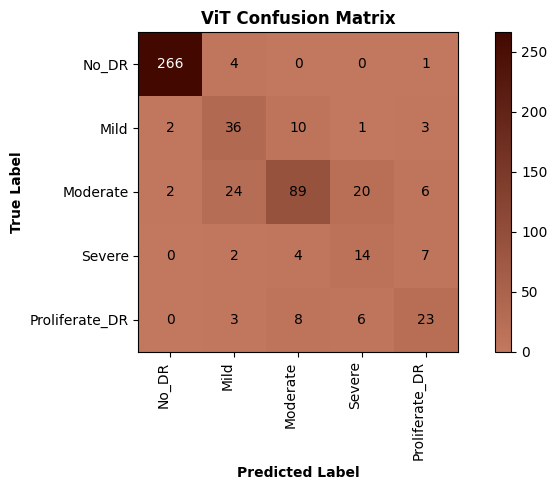

In [ ]:
# Generate the confusion matrix using true and predicted labels.
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))

# Create a custom colour map using the first and last colours from the defined palette.
custom_cmap = LinearSegmentedColormap.from_list("fundus_palette", [PALETTE[0], PALETTE[-1]])

# Set the figure size for the confusion matrix.
plt.figure(figsize=(8, 5))

# Display the confusion matrix with the custom colour map.
plt.imshow(cm, interpolation="nearest", cmap=custom_cmap)

# Add the plot title and display the colour scale.
plt.title("ViT Confusion Matrix", fontweight="bold", color=TEXT_COLOR)
plt.colorbar()

# Set the predicted class labels along the x-axis.
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90, ha="right")

# Set the actual class labels along the y-axis.
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

# Calculate the threshold to determine the annotation text colour.
threshold = cm.max() / 2

# Display the numerical values inside each confusion matrix cell.
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, format(cm[i, j], "d"), ha="center", va="center", color="white" if cm[i, j] > threshold else "black")

# Add labels to the x-axis and y-axis.
plt.xlabel("Predicted Label", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("True Label", fontweight="bold", color=TEXT_COLOR)

# Adjust the layout and display the confusion matrix.
plt.tight_layout()
plt.show()

The ViT confusion matrix shows strong classification of No_DR, with 266 correct predictions. However, misclassifications are observed mainly between Mild and Moderate, and between Severe and Proliferate_DR. Overall, the model performs well for No_DR but requires improvement in distinguishing the other severity levels.

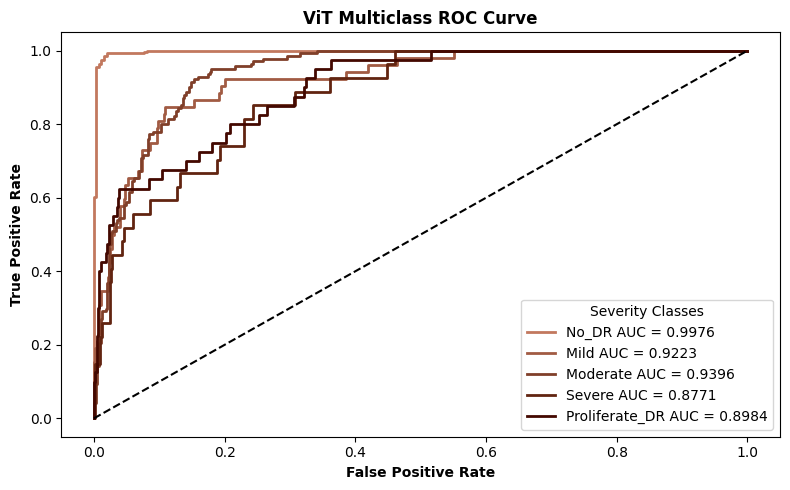

In [ ]:
# Convert the true class labels into binary format for multiclass ROC curve analysis.
y_true_binary = label_binarize(y_true, classes=range(NUM_CLASSES))

# Set the figure size for the ROC curve plot.
plt.figure(figsize=(8, 5))

# Calculate and plot the ROC curve for each severity class.
for i in range(NUM_CLASSES):
    # Calculate the false positive rate, true positive rate and thresholds for each class.
    fpr, tpr, _ = roc_curve(y_true_binary[:, i], y_prob[:, i])

    # Calculate the Area Under the Curve (AUC) for the current class.
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve using the corresponding class colour and AUC score.
    plt.plot(fpr, tpr, color=PALETTE[i], linewidth=2, label=f"{CLASS_NAMES[i]} AUC = {roc_auc:.4f}")

# Plot the diagonal reference line representing random classification performance.
plt.plot([0, 1], [0, 1], linestyle="--", color=TEXT_COLOR)

# Set the plot title and axis labels with bold formatting.
plt.title("ViT Multiclass ROC Curve", fontweight="bold", color=TEXT_COLOR)
plt.xlabel("False Positive Rate", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("True Positive Rate", fontweight="bold", color=TEXT_COLOR)

# Display the legend to identify the colour assigned to each severity class.
plt.legend(loc="lower right", title="Severity Classes")

# Adjust the layout and display the ROC curve.
plt.tight_layout()
plt.show()

The ViT ROC curve shows strong class discrimination, with the highest AUC for No_DR at 0.9976. Mild and Moderate achieve 0.9223 and 0.9396, while Severe and Proliferate_DR record 0.8771 and 0.8984, respectively. Overall, the model demonstrates good classification capability across all severity classes.

### **Swin Transformer Model**



The Swin Transformer uses shifted window-based self-attention to extract important features from fundus images. Its hierarchical architecture captures local and global retinal patterns, enabling effective classification of diabetic retinopathy severity levels.

In [ ]:
# Load the pretrained Swin Transformer Tiny backbone without the classification head.
swin_backbone = SwinTransformerTiny224(include_top=False)

# Enable trainable parameters to allow fine-tuning of the pretrained backbone.
swin_backbone.trainable = True

# Display the model loading status and trainability information.
print("Pretrained Swin Transformer loaded successfully.")
print("Trainable:", swin_backbone.trainable)

177485300/177485300 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Pretrained Swin Transformer loaded successfully.
Trainable: True


In [ ]:
# Display the architecture summary of the Swin Transformer backbone.
swin_backbone.summary()

# Create a dummy input tensor with the specified image dimensions and data type.
dummy_input = tf.zeros((1, IMAGE_SIZE, IMAGE_SIZE, 3), dtype=tf.uint8)

# Pass the dummy input through the Swin Transformer backbone to verify its functionality.
swin_output = swin_backbone(dummy_input)

# Display the output tensor shape generated by the Swin Transformer backbone.
print("Swin output shape:", swin_output.shape)

Model: "swin_tiny_224"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize (Normalization)       │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_embed (PatchEmbedding)    │ (None, None, None, 96) │         4,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pos_drop (Dropout)              │ (None, None, None, 96) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.0 (BasicLayer)           │ (None, None, None, 96) │       224,694 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.0.downsample             │ (None, None, None,     │        74,496 │
│ (PatchMerging)                  │ 192)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.1 (BasicLayer)           │ (None, None, None,     │       891,756 │
│                                 │ 192)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.1.downsample             │ (None, None, None,     │       296,448 │
│ (PatchMerging)                  │ 384)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.2 (BasicLayer)           │ (None, None, None,     │    10,658,952 │
│                                 │ 384)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.2.downsample             │ (None, None, None,     │     1,182,720 │
│ (PatchMerging)                  │ 768)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layers.3 (BasicLayer)           │ (None, None, None,     │    14,183,856 │
│                                 │ 768)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm (LayerNormalization)       │ (None, None, None,     │         1,536 │
│                                 │ 768)                   │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,519,354 (104.98 MB)

 Trainable params: 27,519,354 (104.98 MB)

 Non-trainable params: 0 (0.00 B)

Swin output shape: (1, 7, 7, 768)


In [ ]:
# Define the input layer for 224 × 224 RGB fundus images
inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), dtype=tf.uint8, name="fundus_image")

# Extract hierarchical features using the pretrained Swin Transformer
features = swin_backbone(inputs)

# Apply global average pooling to convert feature maps into a feature vector
features = keras.layers.GlobalAveragePooling2D()(features)

# Add dropout to reduce overfitting
features = keras.layers.Dropout(0.3)(features)

# Add the five-class severity classification layer
outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="severity_predictions")(features)

# Create the complete Swin Transformer classification model
swin_model = keras.Model(inputs=inputs, outputs=outputs, name="Swin_Transformer_DR")

# Display the model architecture
swin_model.summary()

Model: "Swin_Transformer_DR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fundus_image (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ swin_tiny_224 (Functional)      │ (None, 7, 7, 768)      │    27,519,354 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 768)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ severity_predictions (Dense)    │ (None, 5)              │         3,845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,523,199 (104.99 MB)

 Trainable params: 27,523,199 (104.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the Swin Transformer using a low learning rate for fine-tuning
swin_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])

In [ ]:
# Convert the restored training images from float32 to uint8 for Swin Transformer
swin_train_dataset = vit_train_dataset.map(lambda images, labels: (tf.cast(tf.clip_by_value(images, 0.0, 255.0), tf.uint8), labels), num_parallel_calls=tf.data.AUTOTUNE)

# Convert the validation images to uint8
swin_validation_dataset = vit_validation_dataset.map(lambda images, labels: (tf.cast(tf.clip_by_value(images, 0.0, 255.0), tf.uint8), labels), num_parallel_calls=tf.data.AUTOTUNE)

# Convert the test images to uint8
swin_test_dataset = vit_test_dataset.map(lambda images, labels: (tf.cast(tf.clip_by_value(images, 0.0, 255.0), tf.uint8), labels), num_parallel_calls=tf.data.AUTOTUNE)

# Prefetch datasets to improve training performance
swin_train_dataset = swin_train_dataset.prefetch(tf.data.AUTOTUNE)
swin_validation_dataset = swin_validation_dataset.prefetch(tf.data.AUTOTUNE)
swin_test_dataset = swin_test_dataset.prefetch(tf.data.AUTOTUNE)

# Display the dataset specifications
print("Training:", swin_train_dataset.element_spec)
print("Validation:", swin_validation_dataset.element_spec)
print("Testing:", swin_test_dataset.element_spec)

Training: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Validation: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Testing: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [ ]:
# Define callbacks to monitor validation performance and save the best model
swin_callbacks = [
    keras.callbacks.ModelCheckpoint("best_swin_transformer.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1)
]

In [ ]:
# Train and fine-tune the pretrained Swin Transformer
swin_history = swin_model.fit(swin_train_dataset, validation_data=swin_validation_dataset,epochs=8, class_weight=class_weight_dict, callbacks=swin_callbacks, verbose=1)

Epoch 1/8
     78/Unknown 213s 3s/step - accuracy: 0.7867 - loss: 0.7691
Epoch 1: val_accuracy improved from None to 0.78679, saving model to best_swin_transformer.keras

Epoch 1: finished saving model to best_swin_transformer.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 250s 3s/step - accuracy: 0.7845 - loss: 0.7792 - val_accuracy: 0.7868 - val_loss: 0.5677 - learning_rate: 2.0000e-06
Epoch 2/8
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7827 - loss: 0.7410
Epoch 2: val_accuracy did not improve from 0.78679
78/78 ━━━━━━━━━━━━━━━━━━━━ 271s 3s/step - accuracy: 0.7808 - loss: 0.7694 - val_accuracy: 0.7755 - val_loss: 0.5678 - learning_rate: 2.0000e-06
Epoch 3/8
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7701 - loss: 0.7317
Epoch 3: val_accuracy did not improve from 0.78679

Epoch 3: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
78/78 ━━━━━━━━━━━━━━━━━━━━ 251s 3s/step - accuracy: 0.7711 - loss: 0.7524 - val_accuracy: 0.7736 - val_loss: 0.5794 - learning_rate: 2.0

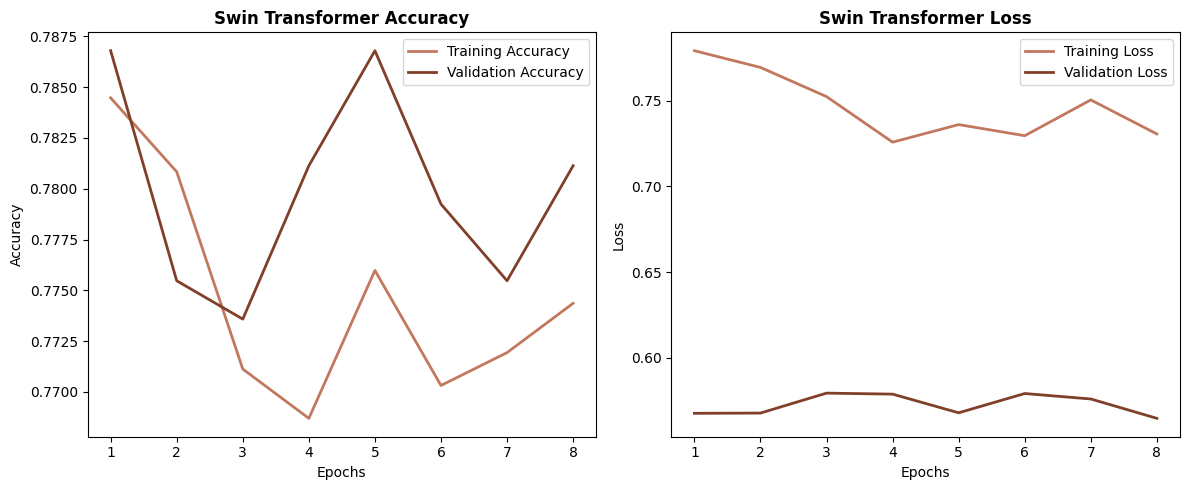

In [ ]:
# Generate the epoch range based on the total number of training epochs.
epochs = range(1, len(swin_history.history["accuracy"]) + 1)

# Create two subplots to display training and validation accuracy and loss side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot training and validation accuracy.
axes[0].plot(epochs, swin_history.history["accuracy"], label="Training Accuracy", color=PALETTE[0], linewidth=2)
axes[0].plot(epochs, swin_history.history["val_accuracy"], label="Validation Accuracy", color=PALETTE[2], linewidth=2)

# Set the title, axis labels and legend for the accuracy plot.
axes[0].set_title("Swin Transformer Accuracy", fontweight="bold", color=TEXT_COLOR)
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Plot training and validation loss.
axes[1].plot(epochs, swin_history.history["loss"], label="Training Loss", color=PALETTE[0], linewidth=2)
axes[1].plot(epochs, swin_history.history["val_loss"], label="Validation Loss", color=PALETTE[2], linewidth=2)

# Set the title, axis labels and legend for the loss plot.
axes[1].set_title("Swin Transformer Loss", fontweight="bold", color=TEXT_COLOR)
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

# Adjust the spacing between subplots and display the learning curves.
plt.tight_layout()
plt.show()

The Swin Transformer training and validation accuracy fluctuate across epochs, with validation accuracy reaching approximately 0.787. Training loss remains relatively stable, while validation loss stays low with minor fluctuations, indicating consistent learning with some variation in performance.

In [ ]:
# Generate class probabilities for the test images
swin_y_prob = swin_model.predict(swin_test_dataset, verbose=1)

# Convert predicted probabilities into class labels
swin_y_pred = np.argmax(swin_y_prob, axis=1)

# Collect the actual labels from the test dataset
swin_y_true = np.concatenate([labels.numpy() for images, labels in swin_test_dataset])

17/17 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step


In [ ]:
# Calculate overall evaluation metrics
swin_accuracy = accuracy_score(swin_y_true, swin_y_pred)
swin_precision = precision_score(swin_y_true, swin_y_pred, average="macro", zero_division=0)
swin_recall = recall_score(swin_y_true, swin_y_pred, average="macro", zero_division=0)
swin_f1 = f1_score(swin_y_true, swin_y_pred, average="macro", zero_division=0)
swin_kappa = cohen_kappa_score(swin_y_true, swin_y_pred)

In [ ]:

# Display the overall evaluation metrics
print("Swin Transformer Model Results:")
print("-"*60)
print(f"Accuracy: {swin_accuracy:.4f}")
print(f"Precision: {swin_precision:.4f}")
print(f"Recall: {swin_recall:.4f}")
print(f"F1-Score: {swin_f1:.4f}")
print(f"Cohen's Kappa: {swin_kappa:.4f}")

Swin Transformer Model Results:
------------------------------------------------------------
Accuracy: 0.8023
Precision: 0.6606
Recall: 0.6734
F1-Score: 0.6533
Cohen's Kappa: 0.7000


The Swin Transformer achieved an accuracy of 0.8023, precision of 0.6606, recall of 0.6734 and F1-score of 0.6533. Cohen’s Kappa of 0.7000 indicates substantial agreement, demonstrating good overall classification performance with scope for improvement.

In [ ]:
# Display the classification report for all five severity classes
print("Swin Transformer Classification Report")
print("-"*60)
print(classification_report(swin_y_true, swin_y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))


Swin Transformer Classification Report
------------------------------------------------------------
                precision    recall  f1-score   support

         No_DR     0.9779    0.9815    0.9797       271
          Mild     0.4744    0.7115    0.5692        52
      Moderate     0.7739    0.6312    0.6953       141
        Severe     0.4103    0.5926    0.4848        27
Proliferate_DR     0.6667    0.4500    0.5373        40

      accuracy                         0.8023       531
     macro avg     0.6606    0.6734    0.6533       531
  weighted avg     0.8221    0.8023    0.8055       531



The Swin Transformer achieved excellent classification for No_DR, with an F1-score of 0.9797. Mild, Moderate, Severe and Proliferate_DR recorded lower F1-scores of 0.5692, 0.6953, 0.4848 and 0.5373, respectively. The weighted F1-score of 0.8055 indicates good overall performance, with scope for improving minority-class classification.

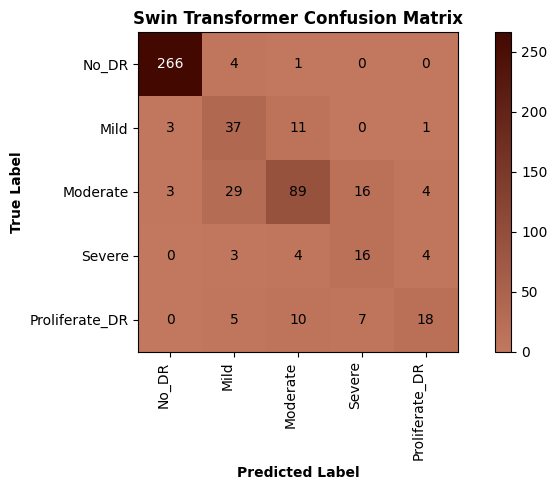

In [ ]:
# Generate the confusion matrix using true and predicted labels.
swin_cm = confusion_matrix(swin_y_true, swin_y_pred, labels=range(NUM_CLASSES))

# Create a custom colour map using the first and last colours from the defined palette.
custom_cmap = LinearSegmentedColormap.from_list("fundus_palette", [PALETTE[0], PALETTE[-1]])

# Set the figure size for the confusion matrix.
plt.figure(figsize=(8, 5))

# Display the confusion matrix with the custom colour map.
plt.imshow(swin_cm, interpolation="nearest", cmap=custom_cmap)

# Add the plot title and display the colour scale.
plt.title("Swin Transformer Confusion Matrix", fontweight="bold", color=TEXT_COLOR)
plt.colorbar()

# Set the predicted class labels along the x-axis.
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90, ha="right")

# Set the actual class labels along the y-axis.
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

# Calculate the threshold to determine the annotation text colour.
threshold = swin_cm.max() / 2

# Display the numerical values inside each confusion matrix cell.
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, format(swin_cm[i, j], "d"), ha="center", va="center", color="white" if swin_cm[i, j] > threshold else "black")

# Add labels to the x-axis and y-axis.
plt.xlabel("Predicted Label", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("True Label", fontweight="bold", color=TEXT_COLOR)

# Adjust the layout and display the confusion matrix.
plt.tight_layout()
plt.show()

The Swin Transformer confusion matrix shows strong classification of No_DR, with 266 correct predictions. Moderate and Mild are frequently misclassified, while some Severe and Proliferate_DR samples are also confused. Overall, the model performs well for No_DR but needs improvement in distinguishing the other severity classes.

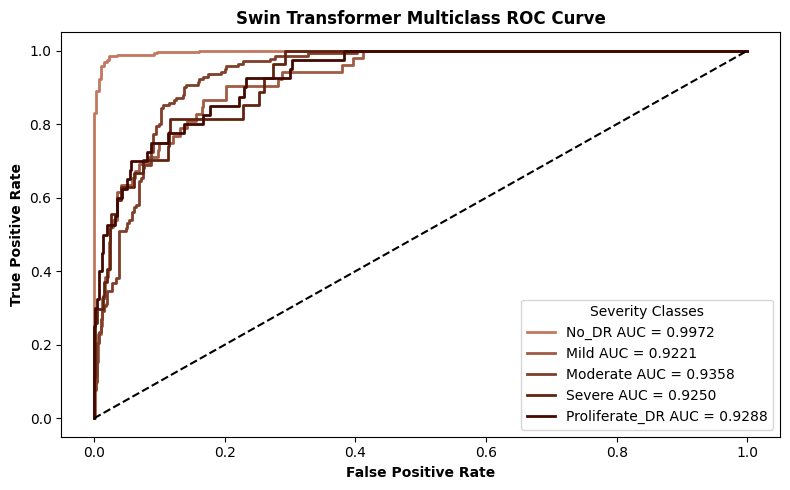

In [ ]:
# Convert the true class labels into binary format for multiclass ROC curve analysis.
swin_y_true_binary = label_binarize(swin_y_true, classes=range(NUM_CLASSES))

# Set the figure size for the ROC curve plot.
plt.figure(figsize=(8, 5))

# Calculate and plot the ROC curve for each severity class.
for i in range(NUM_CLASSES):
    # Calculate the false positive rate, true positive rate and thresholds for each class.
    fpr, tpr, _ = roc_curve(swin_y_true_binary[:, i], swin_y_prob[:, i])

    # Calculate the Area Under the Curve (AUC) for the current class.
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve using the corresponding class colour and AUC score.
    plt.plot(fpr, tpr, color=PALETTE[i], linewidth=2, label=f"{CLASS_NAMES[i]} AUC = {roc_auc:.4f}")

# Plot the diagonal reference line representing random classification performance.
plt.plot([0, 1], [0, 1], linestyle="--", color=TEXT_COLOR)

# Set the plot title and axis labels with bold formatting.
plt.title("Swin Transformer Multiclass ROC Curve", fontweight="bold", color=TEXT_COLOR)
plt.xlabel("False Positive Rate", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("True Positive Rate", fontweight="bold", color=TEXT_COLOR)

# Display the legend to identify the colour assigned to each severity class.
plt.legend(loc="lower right", title="Severity Classes")

# Adjust the layout and display the ROC curve.
plt.tight_layout()
plt.show()

The Swin Transformer ROC curve shows strong class discrimination, with the highest AUC for No_DR at 0.9972. Mild, Moderate, Severe and Proliferate_DR achieve AUC values of 0.9221, 0.9358, 0.9250 and 0.9288, respectively, indicating good classification capability across all severity classes.

### **CNN-ViT Hybrid**



The CNN-ViT Hybrid combines Convolutional Neural Network feature extraction with Vision Transformer self-attention. The CNN captures important local retinal features, while the transformer learns relationships between these features. This combination helps identify complex retinal patterns and improves diabetic retinopathy severity classification.

In [ ]:
# Load the pretrained EfficientNetB0 model without its classification head.
cnn_backbone = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

# Enable fine-tuning of the pretrained CNN backbone.
cnn_backbone.trainable = True

# Display the CNN backbone architecture.
cnn_backbone.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_2     │ (None, 224, 224,  │          7 │ rescaling_4[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_5         │ (None, 224, 224,  │          0 │ normalization_2[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_5[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 4,007,548 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
# Define the input layer for 224 × 224 RGB fundus images.
cnn_inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), dtype=tf.float32, name="fundus_image")

# Extract local retinal features using the pretrained CNN backbone.
cnn_features = cnn_backbone(cnn_inputs, training=False)

# Display the extracted feature map shape.
print("CNN Feature Shape:", cnn_features.shape)

CNN Feature Shape: (None, 7, 7, 1280)


In [ ]:
# Reshape the CNN feature maps into a sequence of feature tokens.
cnn_tokens = keras.layers.Reshape((49, 1280), name="feature_tokens")(cnn_features)

# Apply layer normalisation to the extracted tokens.
cnn_tokens = keras.layers.LayerNormalization(epsilon=1e-6)(cnn_tokens)

# Display the Transformer token shape.
print("CNN-ViT Token Shape:", cnn_tokens.shape)

CNN-ViT Token Shape: (None, 49, 1280)


In [ ]:
# Apply multi-head self-attention to learn relationships between retinal feature tokens.
attention_output = keras.layers.MultiHeadAttention(num_heads=8, key_dim=160, dropout=0.1, name="transformer_attention")(cnn_tokens, cnn_tokens)

# Add a residual connection between the input tokens and attention output.
attention_output = keras.layers.Add()([cnn_tokens, attention_output])

# Apply layer normalisation after the attention operation.
attention_output = keras.layers.LayerNormalization(epsilon=1e-6)(attention_output)

# Display the attention output shape.
print("Transformer Attention Shape:", attention_output.shape)

Transformer Attention Shape: (None, 49, 1280)


In [ ]:
# Expand the token features using a dense layer with GELU activation.
feed_forward = keras.layers.Dense(2560, activation="gelu", name="feed_forward_dense")(attention_output)

# Apply dropout to reduce overfitting.
feed_forward = keras.layers.Dropout(0.1)(feed_forward)

# Project the features back to the original token dimension.
feed_forward = keras.layers.Dense(1280, name="feed_forward_projection")(feed_forward)

# Add a residual connection to preserve the attention features.
transformer_output = keras.layers.Add()([attention_output, feed_forward])

# Apply layer normalisation to the final Transformer features.
transformer_output = keras.layers.LayerNormalization(epsilon=1e-6)(transformer_output)

# Display the final Transformer feature shape.
print("CNN-ViT Feature Shape:", transformer_output.shape)

CNN-ViT Feature Shape: (None, 49, 1280)


In [ ]:
# Convert the Transformer token sequence into a global feature vector.
hybrid_features = keras.layers.GlobalAveragePooling1D(name="global_feature_pooling")(transformer_output)

# Apply dropout to reduce overfitting.
hybrid_features = keras.layers.Dropout(0.3)(hybrid_features)

# Add a fully connected layer for feature learning.
hybrid_features = keras.layers.Dense(512, activation="relu", name="classification_dense")(hybrid_features)

# Apply dropout before the final classification layer.
hybrid_features = keras.layers.Dropout(0.2)(hybrid_features)

# Generate probability predictions for the five diabetic retinopathy severity classes.
hybrid_outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="severity_predictions")(hybrid_features)

# Create the complete CNN-ViT Hybrid classification model.
cnn_vit_model = keras.Model(inputs=cnn_inputs, outputs=hybrid_outputs, name="CNN_ViT_Hybrid")

# Display the complete model architecture.
cnn_vit_model.summary()

Model: "CNN_ViT_Hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ fundus_image        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ fundus_image[0][… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_tokens      │ (None, 49, 1280)  │          0 │ efficientnetb0[0… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 1280)  │      2,560 │ feature_tokens[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_attent… │ (None, 49, 1280)  │  6,558,720 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 49, 1280)  │          0 │ layer_normalizat… │
│                     │                   │            │ transformer_atte… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 1280)  │      2,560 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feed_forward_dense  │ (None, 49, 2560)  │  3,279,360 │ layer_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_54          │ (None, 49, 2560)  │          0 │ feed_forward_den… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feed_forward_proje… │ (None, 49, 1280)  │  3,278,080 │ dropout_54[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 49, 1280)  │          0 │ layer_normalizat… │
│                     │                   │            │ feed_forward_pro… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 1280)  │      2,560 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_feature_poo… │ (None, 1280)      │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_55          │ (None, 1280)      │          0 │ global_feature_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classification_den… │ (None, 512)       │    655,872 │ dropout_55[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_56          │ (None, 512)       │          0 │ classification_d… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ severity_predictio… │ (None, 5)         │      2,565 │ dropout_56[0][0]

 Total params: 17,831,848 (68.02 MB)

 Trainable params: 17,789,825 (67.86 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
# Compile the CNN-ViT Hybrid model using the Adam optimiser.
cnn_vit_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])

In [ ]:
# Convert the training images to float32 format for the CNN backbone.
cnn_vit_train_dataset = swin_train_dataset.map(lambda images, labels: (tf.cast(images, tf.float32), labels), num_parallel_calls=tf.data.AUTOTUNE)

# Convert the validation images to float32 format.
cnn_vit_validation_dataset = swin_validation_dataset.map(lambda images, labels: (tf.cast(images, tf.float32), labels), num_parallel_calls=tf.data.AUTOTUNE)

# Convert the test images to float32 format.
cnn_vit_test_dataset = swin_test_dataset.map(lambda images, labels: (tf.cast(images, tf.float32), labels), num_parallel_calls=tf.data.AUTOTUNE)

# Prefetch the datasets to improve training performance.
cnn_vit_train_dataset = cnn_vit_train_dataset.prefetch(tf.data.AUTOTUNE)
cnn_vit_validation_dataset = cnn_vit_validation_dataset.prefetch(tf.data.AUTOTUNE)
cnn_vit_test_dataset = cnn_vit_test_dataset.prefetch(tf.data.AUTOTUNE)

# Display the dataset specifications.
print("Training:", cnn_vit_train_dataset.element_spec)
print("Validation:", cnn_vit_validation_dataset.element_spec)
print("Testing:", cnn_vit_test_dataset.element_spec)

Training: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Validation: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Testing: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [ ]:
# Define callbacks to monitor validation performance and save the best model.
cnn_vit_callbacks = [
    keras.callbacks.ModelCheckpoint("best_cnn_vit_hybrid.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1)
]

In [ ]:
# Train the CNN-ViT Hybrid model using the training and validation datasets.
cnn_vit_history = cnn_vit_model.fit(cnn_vit_train_dataset, validation_data=cnn_vit_validation_dataset, epochs=8, class_weight=class_weight_dict, callbacks=cnn_vit_callbacks, verbose=1)

Epoch 1/8


2026-11-02 13:01:29.144377: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 13:01:29.295023: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


     77/Unknown 238s 2s/step - accuracy: 0.3770 - loss: 1.6660

2026-11-02 13:04:43.033711: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 13:04:43.171274: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 13:04:46.549864: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 13:04:46.686651: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


     78/Unknown 280s 2s/step - accuracy: 0.3773 - loss: 1.6645
Epoch 1: val_accuracy improved from None to 0.56226, saving model to best_cnn_vit_hybrid.keras

Epoch 1: finished saving model to best_cnn_vit_hybrid.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 327s 3s/step - accuracy: 0.3991 - loss: 1.5555 - val_accuracy: 0.5623 - val_loss: 1.1477 - learning_rate: 1.0000e-05
Epoch 2/8
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5315 - loss: 1.3950
Epoch 2: val_accuracy improved from 0.56226 to 0.66415, saving model to best_cnn_vit_hybrid.keras

Epoch 2: finished saving model to best_cnn_vit_hybrid.keras
78/78 ━━━━━━━━━━━━━━━━━━━━ 214s 3s/step - accuracy: 0.5463 - loss: 1.3433 - val_accuracy: 0.6642 - val_loss: 0.8957 - learning_rate: 1.0000e-05
Epoch 3/8
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5866 - loss: 1.2612
Epoch 3: val_accuracy improved from 0.66415 to 0.69811, saving model to best_cnn_vit_hybrid.keras

Epoch 3: finished saving model to best_cnn_vit_hybrid.keras
78/78 ━━━━━

In [ ]:
# Generate class probabilities for the test images.
cnn_vit_y_prob = cnn_vit_model.predict(cnn_vit_test_dataset, verbose=1)

# Convert predicted probabilities into class labels.
cnn_vit_y_pred = np.argmax(cnn_vit_y_prob, axis=1)

# Collect the actual labels from the test dataset.
cnn_vit_y_true = np.concatenate([labels.numpy() for images, labels in cnn_vit_test_dataset])

17/17 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step


In [ ]:
# Calculate weighted evaluation metrics.
cnn_vit_accuracy = accuracy_score(cnn_vit_y_true, cnn_vit_y_pred)
cnn_vit_precision = precision_score(cnn_vit_y_true, cnn_vit_y_pred, average="weighted", zero_division=0)
cnn_vit_recall = recall_score(cnn_vit_y_true, cnn_vit_y_pred, average="weighted", zero_division=0)
cnn_vit_f1 = f1_score(cnn_vit_y_true, cnn_vit_y_pred, average="weighted", zero_division=0)
cnn_vit_kappa = cohen_kappa_score(cnn_vit_y_true, cnn_vit_y_pred)

In [ ]:
# Display the weighted evaluation metrics.
print("CNN-ViT Hybrid Model Results")
print("-"*60)
print(f"Accuracy: {cnn_vit_accuracy:.4f}")
print(f"Precision: {cnn_vit_precision:.4f}")
print(f"Recall: {cnn_vit_recall:.4f}")
print(f"F1-Score: {cnn_vit_f1:.4f}")
print(f"Cohen's Kappa: {cnn_vit_kappa:.4f}")

CNN-ViT Hybrid Model Results
------------------------------------------------------------
Accuracy: 0.7533
Precision: 0.7723
Recall: 0.7533
F1-Score: 0.7537
Cohen's Kappa: 0.6266


The CNN-ViT Hybrid achieved an accuracy of 0.7533, precision of 0.7723, recall of 0.7533 and F1-score of 0.7537. Cohen’s Kappa of 0.6266 indicates substantial agreement, demonstrating moderate overall classification performance.

In [ ]:
# Display the weighted classification report.
print("CNN-ViT Hybrid Weighted Classification Report")
print("-"*60)
print(classification_report(cnn_vit_y_true, cnn_vit_y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

CNN-ViT Hybrid Weighted Classification Report
------------------------------------------------------------
                precision    recall  f1-score   support

         No_DR     0.9496    0.9742    0.9617       271
          Mild     0.4048    0.6538    0.5000        52
      Moderate     0.7158    0.4823    0.5763       141
        Severe     0.4333    0.4815    0.4561        27
Proliferate_DR     0.4773    0.5250    0.5000        40

      accuracy                         0.7533       531
     macro avg     0.5962    0.6234    0.5988       531
  weighted avg     0.7723    0.7533    0.7537       531



The CNN-ViT Hybrid achieved excellent classification for No_DR, with an F1-score of 0.9617. Mild, Moderate, Severe and Proliferate_DR recorded lower F1-scores of 0.5000, 0.5763, 0.4561 and 0.5000, respectively. The weighted F1-score of 0.7537 indicates moderate overall classification performance.

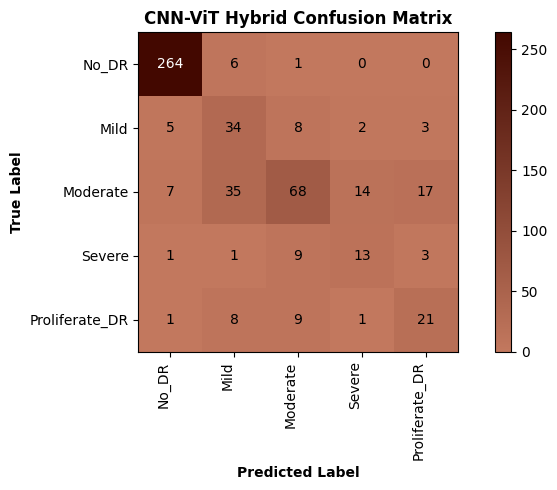

In [ ]:
# Generate the confusion matrix using true and predicted labels.
cnn_vit_cm = confusion_matrix(cnn_vit_y_true, cnn_vit_y_pred, labels=range(NUM_CLASSES))

# Create a custom colour map using the first and last colours from the defined palette.
custom_cmap = LinearSegmentedColormap.from_list("fundus_palette", [PALETTE[0], PALETTE[-1]])

# Set the figure size for the confusion matrix.
plt.figure(figsize=(8, 5))

# Display the confusion matrix with the custom colour map.
plt.imshow(cnn_vit_cm, interpolation="nearest", cmap=custom_cmap)

# Add the plot title and display the colour scale.
plt.title("CNN-ViT Hybrid Confusion Matrix", fontweight="bold", color=TEXT_COLOR)
plt.colorbar()

# Set the predicted class labels along the x-axis.
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90, ha="right")

# Set the actual class labels along the y-axis.
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

# Calculate the threshold to determine the annotation text colour.
threshold = cnn_vit_cm.max() / 2

# Display the numerical values inside each confusion matrix cell.
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, format(cnn_vit_cm[i, j], "d"), ha="center", va="center", color="white" if cnn_vit_cm[i, j] > threshold else "black")

# Add labels to the x-axis and y-axis.
plt.xlabel("Predicted Label", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("True Label", fontweight="bold", color=TEXT_COLOR)

# Adjust the layout and display the confusion matrix.
plt.tight_layout()
plt.show()

The CNN-ViT Hybrid confusion matrix shows strong classification of No_DR, with 264 correct predictions. However, considerable misclassification occurs between Mild and Moderate, with additional errors in Severe and Proliferate_DR. Overall, the model performs well for No_DR but needs improvement in distinguishing the other severity classes.

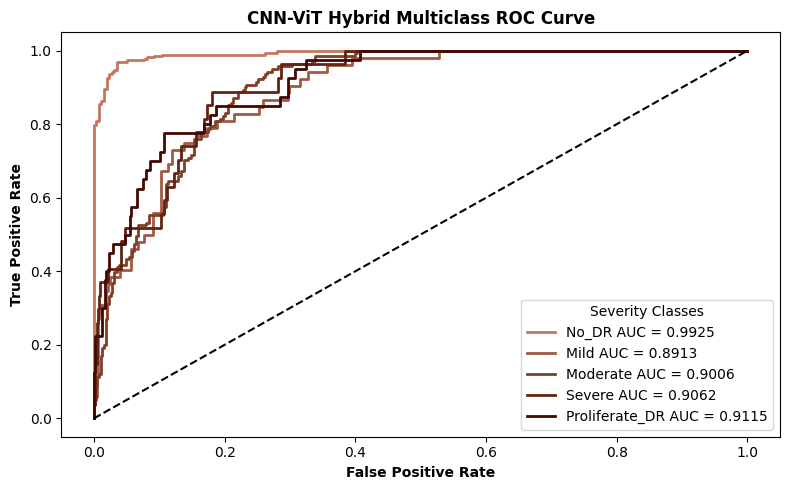

In [ ]:
# Convert the true class labels into binary format for multiclass ROC curve analysis.
cnn_vit_y_true_binary = label_binarize(cnn_vit_y_true, classes=range(NUM_CLASSES))

# Set the figure size for the ROC curve plot.
plt.figure(figsize=(8, 5))

# Calculate and plot the ROC curve for each severity class.
for i in range(NUM_CLASSES):
    # Calculate the false positive rate, true positive rate and thresholds for each class.
    fpr, tpr, _ = roc_curve(cnn_vit_y_true_binary[:, i], cnn_vit_y_prob[:, i])

    # Calculate the Area Under the Curve (AUC) for the current class.
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve using the corresponding class colour and AUC score.
    plt.plot(fpr, tpr, color=PALETTE[i], linewidth=2, label=f"{CLASS_NAMES[i]} AUC = {roc_auc:.4f}")

# Plot the diagonal reference line representing random classification performance.
plt.plot([0, 1], [0, 1], linestyle="--", color=TEXT_COLOR)

# Set the plot title and axis labels with bold formatting.
plt.title("CNN-ViT Hybrid Multiclass ROC Curve", fontweight="bold", color=TEXT_COLOR)
plt.xlabel("False Positive Rate", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("True Positive Rate", fontweight="bold", color=TEXT_COLOR)

# Display the legend to identify the colour assigned to each severity class.
plt.legend(loc="lower right", title="Severity Classes")

# Adjust the layout and display the ROC curve.
plt.tight_layout()
plt.show()

The CNN-ViT Hybrid ROC curve shows strong class discrimination, with the highest AUC for No_DR at 0.9925. Mild, Moderate, Severe and Proliferate_DR achieve AUC values of 0.8913, 0.9006, 0.9062 and 0.9115, respectively, indicating good classification capability across all severity classes.

## **Model Comparison**

In [ ]:
# Create a dictionary containing the evaluation metrics of all four models.
model_results = {
    "Model": ["ViT", "Swin Transformer", "CNN-ViT Hybrid"],
    "Accuracy": [vit_accuracy, swin_accuracy, cnn_vit_accuracy],
    "Precision": [vit_precision, swin_precision, cnn_vit_precision],
    "Recall": [vit_recall, swin_recall, cnn_vit_recall],
    "F1-Score": [vit_f1, swin_f1, cnn_vit_f1],
}

# Convert the model results dictionary into a DataFrame.
model_comparison_df = pd.DataFrame(model_results)

# Display the model comparison DataFrame.
display(model_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,ViT,0.8060,0.8275,0.8060,0.8120
1,Swin Transformer,0.7853,0.6606,0.6734,0.6533
2,CNN-ViT Hybrid,0.7533,0.7723,0.7533,0.7537


The comparison shows that ViT achieved the best overall performance, with the highest accuracy of 0.8060, precision of 0.8275 and F1-score of 0.8120. CNN-ViT Hybrid recorded an F1-score of 0.7537, while Swin Transformer achieved 0.6533. Therefore, ViT was selected as the best-performing model among the three approaches.

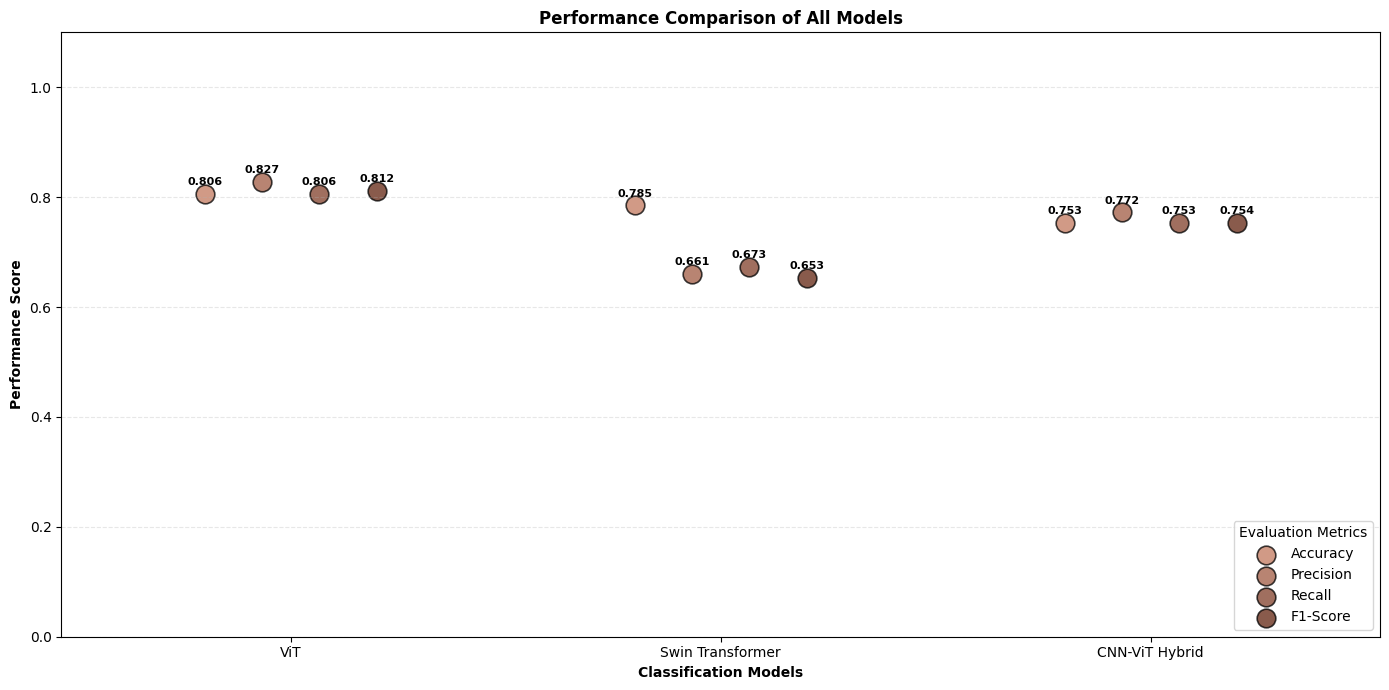

In [ ]:
# Define the evaluation metrics for the bubble plot.
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

# Create the figure and axis for the bubble plot.
plt.figure(figsize=(14, 7))

# Define horizontal positions for the models.
model_positions = np.arange(len(model_comparison_df)) * 1.5

# Define horizontal offsets for each metric.
metric_offsets = np.linspace(-0.3, 0.3, len(metrics))

# Plot each evaluation metric using a different colour.
for i, metric in enumerate(metrics):
    x_positions = model_positions + metric_offsets[i]
    values = model_comparison_df[metric].values

    plt.scatter(x_positions, values, s=180, color=PALETTE[i], alpha=0.75, edgecolors=TEXT_COLOR, linewidth=1.2, label=metric)

    # Display the metric values above each bubble.
    for x, value in zip(x_positions, values):
        plt.text(x, value + 0.012, f"{value:.3f}", ha="center", va="bottom", fontsize=8, fontweight="bold", color=TEXT_COLOR)

# Set the plot title and axis labels.
plt.title("Performance Comparison of All Models", fontweight="bold", color=TEXT_COLOR)
plt.xlabel("Classification Models", fontweight="bold", color=TEXT_COLOR)
plt.ylabel("Performance Score", fontweight="bold", color=TEXT_COLOR)

# Set the x-axis model positions and labels.
plt.xticks(model_positions, model_comparison_df["Model"], rotation=0, ha="center")

# Set the axis limits.
plt.xlim(-0.8, model_positions[-1] + 0.8)
plt.ylim(0, 1.1)

# Add horizontal grid lines for better comparison.
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Display the legend.
plt.legend(title="Evaluation Metrics", loc="lower right")

# Adjust the layout and display the bubble plot.
plt.tight_layout()
plt.show()

## **Save the Best Performing Model**

In [ ]:
# Create the model saving directory.
SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

# Calculate the average performance score.
evaluation_metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
model_comparison_df["Average Score"] = model_comparison_df[evaluation_metrics].mean(axis=1)

# Identify the best-performing model.
best_model_index = model_comparison_df["Average Score"].idxmax()
best_model_name = model_comparison_df.loc[best_model_index, "Model"]
best_model_score = model_comparison_df.loc[best_model_index, "Average Score"]

# Define the model saving path.
model_path = os.path.join(SAVE_DIR, "best_dr_model.keras")

# Save the selected model.
if best_model_name == "ViT":
    vit_model.save(model_path)
elif best_model_name == "Swin Transformer":
    swin_model.save(model_path)
elif best_model_name == "CNN-ViT Hybrid":
    cnn_vit_model.save(model_path)

# Display the saving confirmation.
print("Best Performing Model:", best_model_name)
print("Average Performance Score:", round(best_model_score, 4))
print("Saved Model Path:", model_path)
print("Model Saved:", os.path.exists(model_path))

Best Performing Model: ViT
Average Performance Score: 0.8129
Saved Model Path: /kaggle/working/best_dr_model.keras
Model Saved: True


# Conclusion
This project successfully developed a deep learning-based system for diabetic retinopathy severity grading using fundus images. Three models, ViT, Swin Transformer and CNN-ViT Hybrid, were developed and evaluated using accuracy, precision, recall, F1-score, confusion matrices and ROC curves.

Among the three models, Vision Transformer achieved the best overall performance, with an accuracy of 0.8060, precision of 0.8275, recall of 0.8060 and F1-score of 0.8120. It demonstrated particularly strong classification performance for the No_DR class.

The results highlight the potential of transformer-based architectures for automated diabetic retinopathy classification. Future improvements could focus on enhancing minority-class recognition, addressing class imbalance and evaluating the system using larger and more diverse datasets. The developed approach can support retinal image analysis but is not a replacement for professional ophthalmological diagnosis.